# Intraday data analysis for predicting each stock's same-day price move (original competition notebook, in Korean)
**분 단위 데이터 분석을 통한 종목별 당일 주가 변동 예측 · 제1회 KRX 금융 빅데이터 활용 아이디어 경진대회 · 팀 Micro-A.N.T**

> This is the notebook our team submitted to the 1st KRX Financial Big Data Competition (2022), kept as a record. Saved outputs are from the original run and match the final presentation. Only data-loading bugs that do not affect the outputs were fixed (see the README). **The reported accuracy includes a look-ahead leak** through the `거래대금/시가총액(%)` (trading value / market cap) feature; see `../01_validation_and_leakage.ipynb`. The raw KRX data is not included in this repository.


# 0. 라이브러리 불러오기



In [1]:
# 기본적 modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math 
%matplotlib inline
import seaborn as sns
plt.rc("font", family = "Malgun Gothic")
plt.style.use(['default'])

sns.set(font="Malgun Gothic", rc={"axes.unicode_minus":False}, style='white')
from IPython.display import Image
from numpy import datetime64
from datetime import datetime


# 분석 modules 
import statsmodels.api as sm
from scipy.stats import skew, kurtosis,probplot,anderson
from scipy.stats.mstats import winsorize

# 시각화 modules
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager, rc

# 머신러닝 modules
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.preprocessing import MinMaxScaler

# 딥러닝 modules
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow import optimizers
import tensorflow as tf
from sklearn.model_selection import StratifiedKFold
from keras.models import load_model
from keras.callbacks import EarlyStopping, ModelCheckpoint

# warnings 무시
import warnings
warnings.filterwarnings('ignore')

# 1. 데이터

KRX의 자료를 최대한 활용하고자 **'주식' 파일에 있는 일별 / 일중 / 투자자별 3가지 데이터를 모두 사용**하였습니다. 해당 데이터 중 필요한 컬럼들을 추출한 뒤, '외국인체결강도' , '일중강도' , '외국인순매수' 와 같은 **파생변수**들을 새로이 생성하였습니다.

In [ ]:
import os

#경로 지정해주기
path1 = './일별/' 

path2_1 = './일중/2019/'
path2_2 = './일중/2020/'
path2_3 = './일중/2021/'
path2_4 = './일중/2022/'


path3_1 = './투자자별/2019/'
path3_2 = './투자자별/2020/'
path3_3 = './투자자별/2021/'
path3_4 = './투자자별/2022/'

#파일 리스트 저장하기
file_list1 = os.listdir(path1)  # 일별데이터 불러와서 저장

file_list2_1 = os.listdir(path2_1) # 2019년도 일중데이터
file_list2_2 = os.listdir(path2_2) # 2020년도 일중데이터
file_list2_3 = os.listdir(path2_3) # 2021년도 일중데이터
file_list2_4 = os.listdir(path2_4) # 2022년도 일중데이터

file_list3_1 = os.listdir(path3_1) # 2019년도 투자자별 일중데이터
file_list3_2 = os.listdir(path3_2) # 2020년도 투자자별 일중데이터
file_list3_3 = os.listdir(path3_3) # 2021년도 투자자별 일중데이터
file_list3_4 = os.listdir(path3_4) # 2022년도 투자자별 일중데이터

file_list_py1 = [file for file in file_list1 if file.endswith('.csv')]

file_list_py2_1 = [file for file in file_list2_1 if file.endswith('.csv')]
file_list_py2_2 = [file for file in file_list2_2 if file.endswith('.csv')]
file_list_py2_3 = [file for file in file_list2_3 if file.endswith('.csv')]
file_list_py2_4 = [file for file in file_list2_4 if file.endswith('.csv')]

file_list_py3_1 = [file for file in file_list3_1 if file.endswith('.csv')]
file_list_py3_2 = [file for file in file_list3_2 if file.endswith('.csv')]
file_list_py3_3 = [file for file in file_list3_3 if file.endswith('.csv')]
file_list_py3_4 = [file for file in file_list3_4 if file.endswith('.csv')]

일별데이터 = pd.DataFrame() #일별 데이터 데이터프레임

일중데이터_2019 = pd.DataFrame() # 2019 일중 데이터 데이터프레임

일중데이터_2020 = pd.DataFrame() # 2020 일중 데이터 데이터프레임
일중데이터_2021 = pd.DataFrame() # 2021 일중 데이터 데이터프레임
일중데이터_2022 = pd.DataFrame() # 2022 일중 데이터 데이터프레임

투자자데이터_2019 = pd.DataFrame() # 2019 투자자별 데이터 데이터프레임
투자자데이터_2020 = pd.DataFrame() # 2020 일중 데이터 데이터프레임
투자자데이터_2021 = pd.DataFrame() # 2021 일중 데이터 데이터프레임
투자자데이터_2022 = pd.DataFrame() # 2022 일중 데이터 데이터프레임


## 1.1 일별데이터 load

In [ ]:
#일별csv
for i in file_list_py1:
    data1 = pd.read_csv(path1 + i,encoding='cp949')
    일별데이터 = pd.concat([일별데이터,data1])

## 1.2 일중데이터 load

### 1.2.1 2019년 일중데이터

In [ ]:
#일중csv
for i in file_list_py2_1: # 2019년도 일중데이터
    data2_1 = pd.read_csv(path2_1 + i,encoding='cp949')
    일중데이터_2019 = pd.concat([일중데이터_2019,data2_1])

### 1.2.2 2020년 일중데이터

In [ ]:
for i in file_list_py2_2: # 2020년도 일중데이터
    data2_2 = pd.read_csv(path2_2 + i,encoding='cp949')
    일중데이터_2020 = pd.concat([일중데이터_2020,data2_2])

### 1.2.3 2021년 일중데이터

In [ ]:
for i in file_list_py2_3: # 2021년도 일중데이터
    data2_3 = pd.read_csv(path2_3 + i,encoding='cp949')
    일중데이터_2021 = pd.concat([일중데이터_2021,data2_3])

### 1.2.4 2022년 일중데이터

In [ ]:
for i in file_list_py2_4: # 2022년도 일중데이터
    data2_4 = pd.read_csv(path2_4 + i,encoding='cp949')
    일중데이터_2022 = pd.concat([일중데이터_2022,data2_4])

## 1.3 투자자별데이터 load

### 1.3.1 2019년 투자자별데이터

In [ ]:
#투자자별csv
for i in file_list_py3_1: # 2019년도 투자자별 데이터
    data3_1 = pd.read_csv(path3_1 + i,encoding='cp949')
    투자자데이터_2019 = pd.concat([투자자데이터_2019,data3_1])

### 1.3.2 2020년 투자자별데이터

In [ ]:
#투자자별csv
for i in file_list_py3_2: # 2020년도 투자자별 데이터
    data3_2 = pd.read_csv(path3_2 + i,encoding='cp949')
    투자자데이터_2020 = pd.concat([투자자데이터_2020,data3_2])

### 1.3.3 2021년 투자자별데이터

In [ ]:
#투자자별csv
for i in file_list_py3_3: # 2021년도 투자자별 데이터
    data3_3 = pd.read_csv(path3_3 + i,encoding='cp949')
    투자자데이터_2021 = pd.concat([투자자데이터_2021,data3_3])


### 1.3.4 2022년 투자자별데이터

In [ ]:
for i in file_list_py3_4: # 2022년도 투자자별 데이터
    data3_4 = pd.read_csv(path3_4 + i,encoding='cp949')
    투자자데이터_2022 = pd.concat([투자자데이터_2022,data3_4])

In [ ]:
일별데이터.reset_index(drop = True,inplace=True) # 일별데이터 데이터프레임 인덱스 리셋

일중데이터_2019.reset_index(drop = True,inplace=True)  # 2019년도 일중데이터 데이터프레임 인덱스 리셋
일중데이터_2020.reset_index(drop = True,inplace=True)  # 2020년도 일중데이터 데이터프레임 인덱스 리셋
일중데이터_2021.reset_index(drop = True,inplace=True) # 2021년도 일중데이터 데이터프레임 인덱스 리셋
일중데이터_2022.reset_index(drop = True,inplace=True) # 2022년도 일중데이터 데이터프레임 인덱스 리셋

투자자데이터_2019.reset_index(drop = True,inplace=True) # 2019년도 투자자별 데이터 데이터프레임 인덱스 리셋
투자자데이터_2020.reset_index(drop = True,inplace=True) # 2020년도 투자자별 데이터 데이터프레임 인덱스 리셋
투자자데이터_2021.reset_index(drop = True,inplace=True) # 2021년도 투자자별 데이터 데이터프레임 인덱스 리셋
투자자데이터_2022.reset_index(drop = True,inplace=True) # 2022년도 투자자별 데이터 데이터프레임 인덱스 리셋

## 1.4 거래시각 지정하기 (09:00-11:00)

**목표**: 시장 참여자들의 의사가 반영되어 양질의 정보를 담고있는 **장 초반의 수급 데이터에 주목**하여 장 후반까지의 흐름 예측

전일 미국 증시(09시), 당일 중국 증시 개장(10시 30분)등의 거시경제 움직임을 반영하기 위해 **9시부터 11시까지의 데이터**들로 설명변수를 구성

### 1.4.1 일중데이터 거래시각 추출

In [ ]:
일중데이터_2019 = 일중데이터_2019[(일중데이터_2019['거래시각']>=900) & (일중데이터_2019['거래시각']<=1100)]
일중데이터_2020 = 일중데이터_2020[(일중데이터_2020['거래시각']>=900) & (일중데이터_2020['거래시각']<=1100)]
일중데이터_2021 = 일중데이터_2021[(일중데이터_2021['거래시각']>=900) & (일중데이터_2021['거래시각']<=1100)]
일중데이터_2022 = 일중데이터_2022[(일중데이터_2022['거래시각']>=900) & (일중데이터_2022['거래시각']<=1100)]

list__일중=[]
for i in range(2019,2023):
        list__일중.append(globals()['일중데이터_{}'.format(i)])
df_일중시세정보 = pd.concat(list__일중,ignore_index=True)

## 1.4.2 투자자 데이터 핸들링 

#### **거래시각 추출** 및 **'외국인' 투자자**에만 해당하는 데이터 추출

In [ ]:
외국인데이터_2019=투자자데이터_2019[투자자데이터_2019['투자자구분코드']==9000] #외국인 수급량만을 불러오기
외국인데이터_2019 = 외국인데이터_2019[(외국인데이터_2019['거래시각']>=900) & (외국인데이터_2019['거래시각']<=1100)] #거래시간 데이터

외국인데이터_2020=투자자데이터_2020[투자자데이터_2020['투자자구분코드']==9000] #외국인 수급량만을 불러오기
외국인데이터_2020 = 외국인데이터_2020[(외국인데이터_2020['거래시각']>=900) & (외국인데이터_2020['거래시각']<=1100)] #거래시간 데이터

외국인데이터_2021=투자자데이터_2021[투자자데이터_2021['투자자구분코드']==9000] #외국인 수급량만을 불러오기
외국인데이터_2021 = 외국인데이터_2021[(외국인데이터_2021['거래시각']>=900) & (외국인데이터_2021['거래시각']<=1100)] #거래시간 데이터

외국인데이터_2022=투자자데이터_2022[투자자데이터_2022['투자자구분코드']==9000] #외국인 수급량만을 불러오기
외국인데이터_2022 = 외국인데이터_2022[(투자자데이터_2022['거래시각']>=900) & (외국인데이터_2022['거래시각']<=1100)] #거래시간 데이터

In [ ]:
list__외국인=[]
for i in range(2019,2023):
        list__외국인.append(globals()['외국인데이터_{}'.format(i)])
df_외국인데이터=pd.concat(list__외국인,ignore_index=True)

In [ ]:
일별데이터.to_csv('df_일별시세정보.csv',encoding='cp949')
df_일중시세정보.to_csv('df_일중시세정보.csv',encoding='cp949')
df_외국인데이터.to_csv('df_외국인데이터.csv',encoding='cp949')

# 데이터 로드

In [2]:
df_일별시세정보=pd.read_csv('./df_일별시세정보.csv',encoding='cp949')
df_일중시세정보=pd.read_csv('./df_일중시세정보.csv',encoding='cp949')
df_외국인데이터=pd.read_csv('./df_외국인데이터.csv',encoding='cp949')

# 2. 변수 추출

**설명변수는 총 24가지**이며, 크게 3가지 특성으로 구분하였습니다. 구분한 특성은 다음과 같습니다.
- 수급관련 변수
- 정보비대칭성 변수
- 추세 변수

## 2.1. 수급 관련 변수

### 2.1.1 외국인수급
* 우리나라 증권시장에 큰 영향력을 가지는 외국인투자자의 수급과 관련된 변수들

#### 2.1.1.1 외국인 순매수(도)금액

In [3]:
df_외국인순매수도금액=df_외국인데이터[['종목코드','종목명','거래일자','매수거래대금','매도거래대금']]
df_외국인순매수도금액['외국인순매수(도)금액']=df_외국인순매수도금액['매수거래대금']-df_외국인순매수도금액['매도거래대금']
df_외국인순매수도금액=df_외국인순매수도금액[['종목코드','종목명','거래일자','외국인순매수(도)금액']]
df_외국인순매수도금액=np.round(df_외국인순매수도금액.groupby(['종목코드','종목명','거래일자']).sum()/121,0)
df_외국인순매수도금액.reset_index(inplace=True,drop=False)
df_외국인순매수도금액

,종목코드,종목명,거래일자,외국인순매수(도)금액
0,KR7000020008,동화약품,20190103,-453372.0
1,KR7000020008,동화약품,20190104,-138998.0
2,KR7000020008,동화약품,20190107,-428775.0
3,KR7000020008,동화약품,20190108,-9893.0
4,KR7000020008,동화약품,20190109,19766.0
...,...,...,...,...
195684,KYG5307W1015,엘브이엠씨홀딩스,20191223,-597420.0
195685,KYG5307W1015,엘브이엠씨홀딩스,20191224,56093.0
195686,KYG5307W1015,엘브이엠씨홀딩스,20191226,216288.0
195687,KYG5307W1015,엘브이엠씨홀딩스,20191227,34214.0


#### 2.1.1.2 외국인 순매수(도) 거래량

In [4]:
df_외국인순매수도거래량=df_외국인데이터[['종목코드','거래일자','매수거래량','매도거래량']]
df_외국인순매수도거래량['외국인순매수(도)거래량']=df_외국인순매수도거래량['매수거래량']-df_외국인순매수도거래량['매도거래량']
df_외국인순매수도거래량=df_외국인순매수도거래량[['종목코드','거래일자','외국인순매수(도)거래량']]
df_외국인순매수도거래량=np.round(df_외국인순매수도거래량.groupby(['종목코드','거래일자']).sum()/121,0)
df_외국인순매수도거래량.reset_index(inplace=True,drop=False)
df_외국인순매수도거래량

,종목코드,거래일자,외국인순매수(도)거래량
0,KR7000020008,20190103,-49.0
1,KR7000020008,20190104,-15.0
2,KR7000020008,20190107,-44.0
3,KR7000020008,20190108,-1.0
4,KR7000020008,20190109,2.0
...,...,...,...
195684,KYG5307W1015,20191223,-142.0
195685,KYG5307W1015,20191224,14.0
195686,KYG5307W1015,20191226,53.0
195687,KYG5307W1015,20191227,8.0


#### 2.1.1.3 외국인 체결강도(%)

In [5]:
df_외국인거래실적_체결강도 = df_외국인데이터[['거래일자','종목명','종목코드','매도거래량','매수거래량']]
df_체결강도 = df_외국인거래실적_체결강도.groupby(['종목코드', '거래일자'])['매도거래량','매수거래량'].sum()
df_체결강도['외국인체결강도(%)'] = np.round(df_체결강도['매수거래량'] / df_체결강도['매도거래량'] * 100,4)
df_체결강도.reset_index(inplace=True,drop=False)
df_외국인체결강도=df_체결강도[['종목코드','거래일자','외국인체결강도(%)']]
df_외국인체결강도

,종목코드,거래일자,외국인체결강도(%)
0,KR7000020008,20190103,8.9539
1,KR7000020008,20190104,47.8099
2,KR7000020008,20190107,6.1050
3,KR7000020008,20190108,82.2626
4,KR7000020008,20190109,135.8571
...,...,...,...
195684,KYG5307W1015,20191223,0.0000
195685,KYG5307W1015,20191224,557.3770
195686,KYG5307W1015,20191226,12960.0000
195687,KYG5307W1015,20191227,176.2816


### 2.1.2 일반수급
* 장초반 증권시장 전체 투자자들의 심리를 나타내는 수급과 관련된 변수들

#### 2.1.2.1 수정 거래회전율(%)

 2.1.2.1-1 9시대비 11시 종가 변동 레이블

In [8]:

df_시각뽑기=df_일중시세정보[['종목코드','거래일자','시각']]
df_종가뽑기=df_일중시세정보[['종목코드','거래일자','시각','종가']]
df_시가뽑기=df_일중시세정보[['종목코드','거래일자','시각','시가']]
df_시각뽑기.sort_values(['종목코드','거래일자'],inplace=True)
df_시각뽑기.reset_index(inplace=True,drop=True)
df_시각뽑기.set_index(['종목코드','거래일자'],inplace=True,drop=True)
df_시각뽑기_11시=df_시각뽑기.groupby(['종목코드','거래일자']).max()
df_시각뽑기_9시=df_시각뽑기.groupby(['종목코드','거래일자']).min()
df_시각뽑기_9시.reset_index(inplace=True)
df_시각뽑기_11시.reset_index(inplace=True)

df_9시시가뽑기=pd.merge(df_시각뽑기_9시,df_시가뽑기,on=["종목코드","거래일자","시각"])
df_11시종가뽑기=pd.merge(df_시각뽑기_11시,df_종가뽑기,on=["종목코드","거래일자","시각"])
df_9시시가뽑기.drop(["시각"],inplace=True,axis=1)
df_11시종가뽑기.drop(["시각"],inplace=True,axis=1)
df_9시시가뽑기.rename(columns={"시가":"9시시가"},inplace=True)
df_11시종가뽑기.rename(columns={"종가":"11시종가"},inplace=True)
df_11시_9시변동률=pd.merge(df_9시시가뽑기,df_11시종가뽑기,on=["종목코드","거래일자"])
df_11시_9시변동률["11시_9시변동률(%)"]=((df_11시_9시변동률["11시종가"]-df_11시_9시변동률["9시시가"])/df_11시_9시변동률["9시시가"])*100
df_11시_9시변동률.drop(["9시시가","11시종가"],inplace=True,axis=1)
df_11시_9시변동률["11시9시변동률레이블"]=df_11시_9시변동률["11시_9시변동률(%)"].apply(lambda x : 1 if x> 0 else -1)
df_11시_9시변동률

,종목코드,거래일자,11시_9시변동률(%),11시9시변동률레이블
0,KR7000020008,20190103,-1.820128,-1
1,KR7000020008,20190104,0.439560,1
2,KR7000020008,20190107,0.621118,1
3,KR7000020008,20190108,-0.936524,-1
4,KR7000020008,20190109,0.315126,1
...,...,...,...,...
218862,KYG5307W1015,20191223,-1.976744,-1
218863,KYG5307W1015,20191224,-2.150538,-1
218864,KYG5307W1015,20191226,1.734820,1
218865,KYG5307W1015,20191227,-1.303318,-1


In [9]:
df_시각뽑기=df_일중시세정보[['종목코드','거래일자','시각']]
df_누적거래량뽑기=df_일중시세정보[['종목코드','거래일자','시각','누적거래량']]
df_시각뽑기.sort_values(['종목코드','거래일자'],inplace=True)
df_시각뽑기.reset_index(inplace=True,drop=True)
df_시각뽑기.set_index(['종목코드','거래일자'],inplace=True,drop=True)
df_시각뽑기_11시=df_시각뽑기.groupby(['종목코드','거래일자']).max()
df_시각뽑기_11시.reset_index(inplace=True)
df_11시누적거래량=pd.merge(df_시각뽑기_11시,df_누적거래량뽑기,on=["종목코드","거래일자","시각"])
df_11시누적거래량.drop("시각",inplace=True,axis=1)
df_11시누적거래량


,종목코드,거래일자,누적거래량
0,KR7000020008,20190103,15709
1,KR7000020008,20190104,15151
2,KR7000020008,20190107,77446
3,KR7000020008,20190108,5495
4,KR7000020008,20190109,6577
...,...,...,...
218862,KYG5307W1015,20191223,58809
218863,KYG5307W1015,20191224,59747
218864,KYG5307W1015,20191226,32003
218865,KYG5307W1015,20191227,18802


In [10]:
df_상장주식수=df_일별시세정보[['종목코드','거래일자','상장주식수']]
df_수정거래회전율=pd.merge(df_11시누적거래량,df_상장주식수,on=["종목코드","거래일자"])
df_수정거래회전율=pd.merge(df_수정거래회전율,df_11시_9시변동률,on=["종목코드","거래일자"])
df_수정거래회전율["수정거래회전율(%)"]=(df_수정거래회전율["누적거래량"]/df_수정거래회전율["상장주식수"])*(df_수정거래회전율["11시9시변동률레이블"])*100
df_수정거래회전율.drop(["누적거래량","상장주식수","11시9시변동률레이블","11시_9시변동률(%)"],inplace=True,axis=1)
df_수정거래회전율

,종목코드,거래일자,수정거래회전율(%)
0,KR7000020008,20190103,-0.056241
1,KR7000020008,20190104,0.054243
2,KR7000020008,20190107,0.277271
3,KR7000020008,20190108,-0.019673
4,KR7000020008,20190109,0.023547
...,...,...,...
218862,KYG5307W1015,20191223,-0.115040
218863,KYG5307W1015,20191224,-0.116875
218864,KYG5307W1015,20191226,0.062603
218865,KYG5307W1015,20191227,-0.036780


#### 2.1.2.2 거래대금/시가총액(%)

In [11]:
df_시가총액=df_일별시세정보[['종목코드','거래일자','시가총액']]
df_일중시세정보=pd.merge(df_일중시세정보,df_시가총액,on=['종목코드','거래일자'],how='inner')
df_일중시세정보['거래대금/시가총액(%)'] = df_일중시세정보['거래대금'] / df_일중시세정보['시가총액']
df_거래대금시가총액=pd.DataFrame(df_일중시세정보[['종목코드','거래일자','거래대금/시가총액(%)']])
df_거래대금시가총액=np.round(df_거래대금시가총액.groupby(['종목코드','거래일자']).sum()*100,4)
df_거래대금시가총액.reset_index(inplace=True)
df_거래대금시가총액

,종목코드,거래일자,거래대금/시가총액(%)
0,KR7000020008,20190103,0.0564
1,KR7000020008,20190104,0.0522
2,KR7000020008,20190107,0.2826
3,KR7000020008,20190108,0.0196
4,KR7000020008,20190109,0.0238
...,...,...,...
218862,KYG5307W1015,20191223,0.1156
218863,KYG5307W1015,20191224,0.1186
218864,KYG5307W1015,20191226,0.0607
218865,KYG5307W1015,20191227,0.0368


## 2.2. 정보비대칭성 관련 변수

### *호가단위
- **정보비대칭성 관련 컬럼 생성 시 계산식에서 활용하기 위해 생성한 컬럼**
- 'HS역선택 비용/호가단위',  '평균호가 스프레드/호가단위' 와 같이 활용될 예정

유가증권시장 호가가격단위 (출처: 한국거래소, 2023년 1월 개편 이전 기준)

| 주가 | 호가단위 |
|---|---|
| 1,000원 미만 | 1원 |
| 1,000원 ~ 5,000원 미만 | 5원 |
| 5,000원 ~ 10,000원 미만 | 10원 |
| 10,000원 ~ 50,000원 미만 | 50원 |
| 50,000원 ~ 100,000원 미만 | 100원 |
| 100,000원 ~ 500,000원 미만 | 500원 |
| 500,000원 이상 | 1,000원 |


### 2.2.1 호가비대칭(호가기준)

#### 2.2.1.1 HS역선택 비용/호가단위

In [12]:
df_호가=df_일별시세정보[['종목코드','종목명','거래일자','시가']]
df_호가['호가단위']=""
df_호가['호가단위']=[1000  if (df_호가['시가'][i] >= 500000) 
                       else 500 if (df_호가['시가'][i] >= 100000)
                       else 100 if (df_호가['시가'][i] >= 50000)
                       else 50 if (df_호가['시가'][i] >= 10000) 
                       else 10 if (df_호가['시가'][i] >= 5000) 
                       else 5 if (df_호가['시가'][i] >= 1000)
                       else 1 for i in range(len(df_호가))]
df_호가=df_호가[['종목코드','거래일자','호가단위']]

In [13]:
df_HS역선택비용=pd.merge(df_일중시세정보[["종목코드","거래일자","HS역선택비용"]],df_호가,on=['종목코드','거래일자'],how='inner')
df_HS역선택비용['HS역선택비용/호가단위'] = df_HS역선택비용['HS역선택비용'] / df_HS역선택비용['호가단위']
df_HS역선택비용=df_HS역선택비용[['종목코드','거래일자','HS역선택비용/호가단위']]
df_HS역선택비용=np.round(df_HS역선택비용.groupby(['종목코드','거래일자']).sum()/121,4)
df_HS역선택비용.reset_index(inplace=True)
df_HS역선택비용

,종목코드,거래일자,HS역선택비용/호가단위
0,KR7000020008,20190103,0.6478
1,KR7000020008,20190104,0.3423
2,KR7000020008,20190107,0.5980
3,KR7000020008,20190108,0.6762
4,KR7000020008,20190109,0.2773
...,...,...,...
218862,KYG5307W1015,20191223,1.0701
218863,KYG5307W1015,20191224,2.1045
218864,KYG5307W1015,20191226,0.8091
218865,KYG5307W1015,20191227,0.7536


#### 2.2.1.2 평균호가스프레드/호가단위

In [14]:
df_평균호가스프레드=pd.merge(df_일중시세정보[["종목코드","거래일자","평균호가스프레드"]],df_호가,on=['종목코드','거래일자'],how='inner')
df_평균호가스프레드['평균호가스프레드/호가단위'] = df_평균호가스프레드['평균호가스프레드'] / df_평균호가스프레드['호가단위']
df_평균호가스프레드=df_평균호가스프레드[['종목코드','거래일자','평균호가스프레드/호가단위']]
df_평균호가스프레드=np.round(df_평균호가스프레드.groupby(['종목코드','거래일자']).sum()/121,4)
df_평균호가스프레드.reset_index(inplace=True)
df_평균호가스프레드

,종목코드,거래일자,평균호가스프레드/호가단위
0,KR7000020008,20190103,1.1120
1,KR7000020008,20190104,1.2476
2,KR7000020008,20190107,2.7621
3,KR7000020008,20190108,1.6317
4,KR7000020008,20190109,1.7239
...,...,...,...
218862,KYG5307W1015,20191223,1.2486
218863,KYG5307W1015,20191224,1.6618
218864,KYG5307W1015,20191226,1.0659
218865,KYG5307W1015,20191227,1.1975


#### 2.2.1.3 평균비율스프레드

In [15]:
df_평균비율스프레드=df_일중시세정보[['종목코드','거래일자','평균비율스프레드']]
df_평균비율스프레드=np.round(df_평균비율스프레드.groupby(['종목코드','거래일자']).sum()/121,4)
df_평균비율스프레드.reset_index(inplace=True)
df_평균비율스프레드

,종목코드,거래일자,평균비율스프레드
0,KR7000020008,20190103,0.1191
1,KR7000020008,20190104,0.1387
2,KR7000020008,20190107,0.2595
3,KR7000020008,20190108,0.1704
4,KR7000020008,20190109,0.1706
...,...,...,...
218862,KYG5307W1015,20191223,0.1426
218863,KYG5307W1015,20191224,0.2037
218864,KYG5307W1015,20191226,0.1350
218865,KYG5307W1015,20191227,0.1541


#### 2.2.1.4 주문건수기준깊이

In [16]:
df_주문건수기준깊이=df_일중시세정보[['종목코드','거래일자','주문건수기준깊이']]
df_주문건수기준깊이=np.round(df_주문건수기준깊이.groupby(['종목코드','거래일자']).sum()/121,4)
df_주문건수기준깊이.reset_index(inplace=True)
df_주문건수기준깊이

,종목코드,거래일자,주문건수기준깊이
0,KR7000020008,20190103,1.8595
1,KR7000020008,20190104,0.4752
2,KR7000020008,20190107,1.5661
3,KR7000020008,20190108,0.4050
4,KR7000020008,20190109,0.4711
...,...,...,...
218862,KYG5307W1015,20191223,1.3802
218863,KYG5307W1015,20191224,1.9132
218864,KYG5307W1015,20191226,0.9628
218865,KYG5307W1015,20191227,0.6612


#### 2.2.1.5 주문수량기준깊이

In [17]:
df_주문수량기준깊이=df_일중시세정보[['종목코드','거래일자','주문수량기준깊이']]
df_주문수량기준깊이=np.round(df_주문수량기준깊이.groupby(['종목코드','거래일자']).sum()/121,4)
df_주문수량기준깊이.reset_index(inplace=True)
df_주문수량기준깊이

,종목코드,거래일자,주문수량기준깊이
0,KR7000020008,20190103,191.9917
1,KR7000020008,20190104,103.0413
2,KR7000020008,20190107,201.0868
3,KR7000020008,20190108,37.5207
4,KR7000020008,20190109,90.2769
...,...,...,...
218862,KYG5307W1015,20191223,871.9215
218863,KYG5307W1015,20191224,492.1033
218864,KYG5307W1015,20191226,535.9545
218865,KYG5307W1015,20191227,533.6736


#### 2.2.1.6 전량가중평균지정가/종가

In [18]:
df_전량가중평균지정가=df_일중시세정보[['종목코드','거래일자','전량가중평균지정가','종가']]
df_전량가중평균지정가 = df_전량가중평균지정가.replace(0,np.NaN)
df_전량가중평균지정가.reset_index(inplace=True,drop=True)

df_전량가중평균지정가_1=df_전량가중평균지정가.groupby(['종목코드', '거래일자'])['전량가중평균지정가'].bfill().ffill()
df_전량가중평균지정가['전량가중평균지정가']=df_전량가중평균지정가_1
df_전량가중평균지정가['전량가중평균지정가/종가']=df_전량가중평균지정가['전량가중평균지정가']/df_전량가중평균지정가['종가']
df_전량가중평균지정가.drop(['종가','전량가중평균지정가'],axis=1,inplace=True)
df_전량가중평균지정가=np.round(df_전량가중평균지정가.groupby(['종목코드','거래일자']).sum()/121,4)
df_전량가중평균지정가.reset_index(inplace=True)
df_전량가중평균지정가

,종목코드,거래일자,전량가중평균지정가/종가
0,KR7000020008,20190103,0.6695
1,KR7000020008,20190104,0.3381
2,KR7000020008,20190107,0.5537
3,KR7000020008,20190108,0.3050
4,KR7000020008,20190109,0.4052
...,...,...,...
218862,KYG5307W1015,20191223,0.5870
218863,KYG5307W1015,20191224,0.6710
218864,KYG5307W1015,20191226,0.5622
218865,KYG5307W1015,20191227,0.5386


### 2.2.2 빈도비대칭(빈도기준)

#### 2.2.2.1  주문빈도기준취소율

In [19]:
df_주문빈도기준취소율=df_일중시세정보[['종목코드','거래일자','주문빈도기준취소율']]
df_주문빈도기준취소율 = df_주문빈도기준취소율.replace(0,np.NaN)
df_주문빈도기준취소율.reset_index(inplace=True,drop=True)

df_주문빈도기준취소율_1=df_주문빈도기준취소율.groupby(['종목코드', '거래일자'])['주문빈도기준취소율'].bfill().ffill()
df_주문빈도기준취소율['주문빈도기준취소율']=df_주문빈도기준취소율_1
df_주문빈도기준취소율=np.round(df_주문빈도기준취소율.groupby(['종목코드','거래일자']).sum()/121,4)
df_주문빈도기준취소율.reset_index(inplace=True)
df_주문빈도기준취소율

,종목코드,거래일자,주문빈도기준취소율
0,KR7000020008,20190103,0.1294
1,KR7000020008,20190104,0.0770
2,KR7000020008,20190107,0.1292
3,KR7000020008,20190108,0.0725
4,KR7000020008,20190109,0.1080
...,...,...,...
218862,KYG5307W1015,20191223,0.1271
218863,KYG5307W1015,20191224,0.1606
218864,KYG5307W1015,20191226,0.1198
218865,KYG5307W1015,20191227,0.1247


#### 2.2.2.2  종목별거래횟수기준매수매도불균형

In [20]:
df_종목별거래횟수기준매수매도불균형=df_일중시세정보[['종목코드','거래일자','종목별거래횟수기준매수매도불균형']]
df_종목별거래횟수기준매수매도불균형.dropna(subset=['종목별거래횟수기준매수매도불균형'],inplace=True,axis=0)
df_종목별거래횟수기준매수매도불균형=df_종목별거래횟수기준매수매도불균형.groupby(['종목코드','거래일자']).mean()
df_종목별거래횟수기준매수매도불균형.reset_index(inplace=True)
df_종목별거래횟수기준매수매도불균형

,종목코드,거래일자,종목별거래횟수기준매수매도불균형
0,KR7000020008,20190103,0.487777
1,KR7000020008,20190104,0.508732
2,KR7000020008,20190107,0.575502
3,KR7000020008,20190108,0.486421
4,KR7000020008,20190109,0.476466
...,...,...,...
218862,KYG5307W1015,20191223,0.576536
218863,KYG5307W1015,20191224,0.555621
218864,KYG5307W1015,20191226,0.717840
218865,KYG5307W1015,20191227,0.577198


#### 2.2.2.3  주문횟수기준주문불균형

In [21]:
df_주문횟수기준주문불균형=df_일중시세정보[['종목코드','거래일자','주문횟수기준주문불균형']]
df_주문횟수기준주문불균형=np.round(df_주문횟수기준주문불균형.groupby(['종목코드','거래일자']).sum()/121,4)
df_주문횟수기준주문불균형.reset_index(inplace=True)
df_주문횟수기준주문불균형

,종목코드,거래일자,주문횟수기준주문불균형
0,KR7000020008,20190103,0.5855
1,KR7000020008,20190104,0.2078
2,KR7000020008,20190107,0.5587
3,KR7000020008,20190108,0.3577
4,KR7000020008,20190109,0.3170
...,...,...,...
218862,KYG5307W1015,20191223,1.1389
218863,KYG5307W1015,20191224,1.1530
218864,KYG5307W1015,20191226,1.0014
218865,KYG5307W1015,20191227,0.6676


### 2.2.3 거래량비대칭(거래량기준)

#### 2.2.3.1  주문량기준취소율

In [22]:
df_주문량기준취소율=df_일중시세정보[['종목코드','거래일자','주문량기준취소율']]
df_주문량기준취소율 = df_주문량기준취소율.replace(0,np.NaN)
df_주문량기준취소율.reset_index(inplace=True,drop=True)

df_주문량기준취소율_1=df_주문량기준취소율.groupby(['종목코드', '거래일자'])['주문량기준취소율'].bfill().ffill()
df_주문량기준취소율['주문량기준취소율']=df_주문량기준취소율_1
df_주문량기준취소율=np.round(df_주문량기준취소율.groupby(['종목코드','거래일자']).sum()/121,4)
df_주문량기준취소율.reset_index(inplace=True)
df_주문량기준취소율

,종목코드,거래일자,주문량기준취소율
0,KR7000020008,20190103,0.1270
1,KR7000020008,20190104,0.0621
2,KR7000020008,20190107,0.0908
3,KR7000020008,20190108,0.0874
4,KR7000020008,20190109,0.0930
...,...,...,...
218862,KYG5307W1015,20191223,0.2057
218863,KYG5307W1015,20191224,0.1744
218864,KYG5307W1015,20191226,0.1778
218865,KYG5307W1015,20191227,0.1082


#### 2.2.3.2 종목별거래량기준매수매도불균형

In [23]:
df_종목별거래량기준매수매도불균형=df_일중시세정보[['종목코드','거래일자','종목별거래량기준매수매도불균형']]
df_종목별거래량기준매수매도불균형.dropna(subset=['종목별거래량기준매수매도불균형'],inplace=True,axis=0)
df_종목별거래량기준매수매도불균형=df_종목별거래량기준매수매도불균형.groupby(['종목코드','거래일자']).mean()
df_종목별거래량기준매수매도불균형.reset_index(inplace=True)
df_종목별거래량기준매수매도불균형

,종목코드,거래일자,종목별거래량기준매수매도불균형
0,KR7000020008,20190103,0.353315
1,KR7000020008,20190104,0.385070
2,KR7000020008,20190107,0.578118
3,KR7000020008,20190108,0.469438
4,KR7000020008,20190109,0.262784
...,...,...,...
206041,KYG5307W1015,20191223,0.328081
206042,KYG5307W1015,20191224,0.379489
206043,KYG5307W1015,20191226,0.346900
206044,KYG5307W1015,20191227,0.317801


#### 2.2.3.3 주문량기준주문불균형

In [24]:
df_주문량기준주문불균형=df_일중시세정보[['종목코드','거래일자','주문량기준주문불균형']]
df_주문량기준주문불균형=np.round(df_주문량기준주문불균형.groupby(['종목코드','거래일자']).sum()/121,4)
df_주문량기준주문불균형.reset_index(inplace=True)
df_주문량기준주문불균형

,종목코드,거래일자,주문량기준주문불균형
0,KR7000020008,20190103,8.6460
1,KR7000020008,20190104,7.7056
2,KR7000020008,20190107,43.8697
3,KR7000020008,20190108,3.4635
4,KR7000020008,20190109,3.4910
...,...,...,...
218862,KYG5307W1015,20191223,2.8300
218863,KYG5307W1015,20191224,27.0327
218864,KYG5307W1015,20191226,53.2927
218865,KYG5307W1015,20191227,8.1040


## 2.3. 추세 변수

### 2.3.1 위치지표
* 장 초반 종목들의 움직임이 추세상 어느 위치에 있는지로부터 정보를 얻고자 하는 변수

#### 2.3.1.1 TRIN(Inverted)(Arms Index)

In [25]:
df_시가=df_일별시세정보[['종목코드','거래일자','시가']]

df_TRIN_시각=df_일중시세정보[['종목코드','종목명','거래일자','시각']]
df_TRIN_종가=df_일중시세정보[['종목코드','종목명','거래일자','시각','종가']]
df_TRIN_시각.sort_values(['종목명','거래일자'],inplace=True)
df_TRIN_시각.reset_index(inplace=True,drop=True)
df_TRIN_시각.set_index(['종목코드','종목명','거래일자'],inplace=True,drop=True)
df_TRIN_시각=df_TRIN_시각.groupby(['종목코드','종목명','거래일자']).max()

df_TRIN_종가최종=pd.merge(df_TRIN_시각,df_TRIN_종가,on=['종목코드','종목명','거래일자','시각'],how='inner')

df_일중시세정보_고가=df_일중시세정보[['종목코드','거래일자','고가']]
df_일중시세정보_고가=df_일중시세정보_고가.groupby(['종목코드','거래일자']).max()
df_일중시세정보_고가.reset_index(inplace=True)

df_일중시세정보_저가=df_일중시세정보[['종목코드','거래일자','저가']]
df_일중시세정보_저가=df_일중시세정보_저가.groupby(['종목코드','거래일자']).min()
df_일중시세정보_저가.reset_index(inplace=True)

df_TRIN=pd.merge(df_TRIN_종가최종,df_일중시세정보_저가,on=['종목코드','거래일자'],how='inner')
df_TRIN=pd.merge(df_TRIN,df_일중시세정보_고가,on=['종목코드','거래일자'],how='inner')
df_TRIN=pd.merge(df_TRIN,df_11시누적거래량,on=['종목코드','거래일자'],how='inner')
df_TRIN=pd.merge(df_TRIN,df_시가,on=['종목코드','거래일자'],how='inner')
df_TRIN["TRIN(Inverted)"]=(df_TRIN["고가"]*df_TRIN["종가"])/(df_TRIN["시가"]*df_TRIN["누적거래량"])
df_TRIN.drop(["종목명","시각","종가","시가","저가","누적거래량","고가"],inplace=True,axis=1)
df_TRIN["TRIN(Inverted)레이블"]=df_TRIN["TRIN(Inverted)"].apply(lambda x: 2 if x>=3 else 1 if x>0.5 else 0)
df_TRIN.drop(["TRIN(Inverted)"],axis=1,inplace=True)
df_TRIN.rename(columns={"TRIN(Inverted)레이블":"TRIN(Inverted)"},inplace=True)
df_TRIN

,종목코드,거래일자,TRIN(Inverted)
0,KR7000020008,20190103,1
1,KR7000020008,20190104,1
2,KR7000020008,20190107,0
3,KR7000020008,20190108,1
4,KR7000020008,20190109,1
...,...,...,...
218862,KYG5307W1015,20191223,0
218863,KYG5307W1015,20191224,0
218864,KYG5307W1015,20191226,0
218865,KYG5307W1015,20191227,0


#### 2.3.1.2 PPP(Pivot Point Position)

In [26]:
df_일별시세정보_sh=df_일별시세정보[["거래일자","종목명","종목코드","시가","종가","저가","고가"]]

df_일별시세정보_sh["피봇포인트"]=round((df_일별시세정보_sh["고가"]+df_일별시세정보_sh["저가"]+df_일별시세정보_sh["종가"])/3,2)
df_일별시세정보_sh["2차저항선"]=df_일별시세정보_sh["피봇포인트"]+df_일별시세정보_sh["고가"]-df_일별시세정보_sh["저가"]
df_일별시세정보_sh["1차저항선"]=2*df_일별시세정보_sh["피봇포인트"]-df_일별시세정보_sh["저가"]
df_일별시세정보_sh["1차지지선"]=2*df_일별시세정보_sh["피봇포인트"]-df_일별시세정보_sh["고가"]
df_일별시세정보_sh["2차지지선"]=df_일별시세정보_sh["피봇포인트"]-df_일별시세정보_sh["고가"]+df_일별시세정보_sh["저가"]
df_일별시세정보_sh['거래일자_1']=df_일별시세정보_sh['거래일자']
df_일별시세정보_sh['거래일자']=df_일별시세정보_sh['거래일자'].astype(str)
df_일별시세정보_sh['거래일자']=df_일별시세정보_sh['거래일자'].apply(lambda _ : datetime.strptime(_,'%Y%m%d'))

df_일별시세정보_sh=df_일별시세정보_sh.sort_values(by=["종목코드","거래일자"],ascending=True)
df_일별시세정보_sh["피봇포인트_sh"]=df_일별시세정보_sh.groupby(["종목코드"])["피봇포인트"].shift(1)
df_일별시세정보_sh["2차저항선_sh"]=df_일별시세정보_sh.groupby(["종목코드"])["2차저항선"].shift(1)
df_일별시세정보_sh["1차저항선_sh"]=df_일별시세정보_sh.groupby(["종목코드"])["1차저항선"].shift(1)
df_일별시세정보_sh["1차지지선_sh"]=df_일별시세정보_sh.groupby(["종목코드"])["1차지지선"].shift(1)
df_일별시세정보_sh["2차지지선_sh"]=df_일별시세정보_sh.groupby(["종목코드"])["2차지지선"].shift(1)

df_일별시세정보_sh_1=df_일별시세정보_sh[["종목코드","거래일자","피봇포인트_sh","2차저항선_sh","1차저항선_sh","1차지지선_sh","2차지지선_sh","거래일자_1"]]
df_일별시세정보_sh_1.rename(columns={"거래일자":"거래일자_sh","거래일자_1":"거래일자"},inplace=True)

df_피봇_시각=df_일중시세정보[['종목코드','종목명','거래일자','시각']]
df_피봇_종가=df_일중시세정보[['종목코드','종목명','거래일자','시각','종가']]
df_피봇_시각.sort_values(['종목명','거래일자'],inplace=True)
df_피봇_시각.reset_index(inplace=True,drop=True)
df_피봇_시각.set_index(['종목코드','종목명','거래일자'],inplace=True,drop=True)
df_피봇_시각=df_피봇_시각.groupby(['종목코드','종목명','거래일자']).max()

df_피봇_종가최종=pd.merge(df_피봇_시각,df_피봇_종가,on=['종목코드','종목명','거래일자','시각'],how='inner')
df_피봇_종가최종.drop(["시각","종목명"],inplace=True,axis=1)
df_피봇_종가최종.rename(columns={"종가":"11시종가"},inplace=True)


df_PPP=pd.merge(df_피봇_종가최종,df_일별시세정보_sh_1,on=["종목코드","거래일자"])
df_PPP.drop(["거래일자_sh"],axis=1,inplace=True)
df_PPP["PPP"]=""
df_PPP["PPP"]=[2  if (df_PPP['11시종가'][i] > df_PPP['2차저항선_sh'][i]) 
                       else 1 if (df_PPP['11시종가'][i] > df_PPP['1차저항선_sh'][i]) 
                       else 0 if (df_PPP['11시종가'][i] > df_PPP['1차지지선_sh'][i])
                       else -1 if (df_PPP['11시종가'][i] > df_PPP['2차지지선_sh'][i]) 
                       else -2 if (df_PPP['11시종가'][i] <= df_PPP['1차지지선_sh'][i]) 
                       else 0 for i in range(len(df_PPP))]

df_PPP.dropna(inplace=True)
df_PPP.drop(["11시종가","피봇포인트_sh","1차저항선_sh","2차저항선_sh","1차지지선_sh","2차지지선_sh"],axis=1,inplace=True)
df_PPP


,종목코드,거래일자,PPP
0,KR7000020008,20190103,0
1,KR7000020008,20190104,0
2,KR7000020008,20190107,0
3,KR7000020008,20190108,0
4,KR7000020008,20190109,0
...,...,...,...
218862,KYG5307W1015,20191223,-1
218863,KYG5307W1015,20191224,-2
218864,KYG5307W1015,20191226,0
218865,KYG5307W1015,20191227,0


#### 2.3.1.3 MFI(Money Flow Index)

In [27]:
df_일별시세정보_MFI_sh=df_일별시세정보[["거래일자","종목명","종목코드","시가","종가","저가","고가"]]
df_일별시세정보_MFI_sh["기준가격"]=round((df_일별시세정보_MFI_sh["고가"]+df_일별시세정보_MFI_sh["저가"]+df_일별시세정보_MFI_sh["종가"])/3,2)
df_일별시세정보_MFI_sh=df_일별시세정보_MFI_sh.sort_values(by=["종목코드","거래일자"],ascending=True)
df_일별시세정보_MFI_sh["기준가격_sh"]=df_일별시세정보_MFI_sh.groupby(["종목코드"])["기준가격"].shift(1)


df_일별시세정보_MFI_sh_1=df_일별시세정보_MFI_sh[["종목코드","거래일자","기준가격","기준가격_sh"]]
df_일중시세정보_시간별종가=df_일중시세정보[['종목코드','거래일자','시각','종가']]

df_MFI_최종=pd.merge(df_일중시세정보_시간별종가,df_일별시세정보_MFI_sh_1,on=["종목코드","거래일자"])
df_MFI_최종["PMF"]=df_MFI_최종.apply(lambda x:1 if x.종가 > x.기준가격_sh else 0, axis='columns')
df_MFI_최종=df_MFI_최종[["종목코드","거래일자","시각","PMF"]]
df_MFI_최종=df_MFI_최종.groupby(["종목코드","거래일자"]).sum()
df_MFI_최종.drop("시각",inplace=True,axis=1)
df_MFI_최종["MR"]=(df_MFI_최종["PMF"])/(121-df_MFI_최종["PMF"])
df_MFI_최종["MFI"]=100-(100/(1+df_MFI_최종["MR"]))
df_MFI_최종.reset_index(inplace=True)
df_MFI_최종=df_MFI_최종[["종목코드","거래일자","MFI"]]
df_MFI_최종

,종목코드,거래일자,MFI
0,KR7000020008,20190103,7.438017
1,KR7000020008,20190104,0.000000
2,KR7000020008,20190107,55.371901
3,KR7000020008,20190108,0.000000
4,KR7000020008,20190109,40.495868
...,...,...,...
218862,KYG5307W1015,20191223,0.826446
218863,KYG5307W1015,20191224,0.000000
218864,KYG5307W1015,20191226,54.545455
218865,KYG5307W1015,20191227,46.280992


#### 2.3.1.4 일중강도/거래량(%)

In [28]:
df_시각뽑기=df_일중시세정보[['종목코드','거래일자','시각']]
df_누적거래량뽑기=df_일중시세정보[['종목코드','거래일자','시각','누적거래량']]
df_시각뽑기.sort_values(['종목코드','거래일자'],inplace=True)
df_시각뽑기.reset_index(inplace=True,drop=True)
df_시각뽑기.set_index(['종목코드','거래일자'],inplace=True,drop=True)
df_시각뽑기_11시=df_시각뽑기.groupby(['종목코드','거래일자']).max()
df_시각뽑기_11시.reset_index(inplace=True)
df_11시누적거래량=pd.merge(df_시각뽑기_11시,df_누적거래량뽑기,on=["종목코드","거래일자","시각"])
df_11시누적거래량.drop("시각",inplace=True,axis=1)

df_일중강도_시각=df_일중시세정보[['종목코드','종목명','거래일자','시각']]
df_일중강도_종가=df_일중시세정보[['종목코드','종목명','거래일자','시각','종가']]
df_일중강도_시각.sort_values(['종목명','거래일자'],inplace=True)
df_일중강도_시각.reset_index(inplace=True,drop=True)
df_일중강도_시각.set_index(['종목코드','종목명','거래일자'],inplace=True,drop=True)
df_일중강도_시각=df_일중강도_시각.groupby(['종목코드','종목명','거래일자']).max()

df_일중강도_종가최종=pd.merge(df_일중강도_시각,df_일중강도_종가,on=['종목코드','종목명','거래일자','시각'],how='inner')

df_일중시세정보_고가=df_일중시세정보[['종목코드','거래일자','고가']]
df_일중시세정보_고가=df_일중시세정보_고가.groupby(['종목코드','거래일자']).max()
df_일중시세정보_고가.reset_index(inplace=True)

df_일중시세정보_저가=df_일중시세정보[['종목코드','거래일자','저가']]
df_일중시세정보_저가=df_일중시세정보_저가.groupby(['종목코드','거래일자']).min()
df_일중시세정보_저가.reset_index(inplace=True)

df_일중강도=pd.merge(df_일중강도_종가최종,df_일중시세정보_저가,on=['종목코드','거래일자'],how='inner')
df_일중강도=pd.merge(df_일중강도,df_일중시세정보_고가,on=['종목코드','거래일자'],how='inner')

df_일중강도['일중강도/거래량(%)']=((2*df_일중강도['종가']-df_일중강도['고가']-df_일중강도['저가'])/(df_일중강도['고가']-df_일중강도['저가']))*100
df_일중강도=pd.DataFrame(df_일중강도[['종목코드','거래일자','일중강도/거래량(%)']])
df_일중강도

,종목코드,거래일자,일중강도/거래량(%)
0,KR7000020008,20190103,-69.230769
1,KR7000020008,20190104,-38.461538
2,KR7000020008,20190107,44.827586
3,KR7000020008,20190108,0.000000
4,KR7000020008,20190109,-16.666667
...,...,...,...
218862,KYG5307W1015,20191223,-36.000000
218863,KYG5307W1015,20191224,36.842105
218864,KYG5307W1015,20191226,87.500000
218865,KYG5307W1015,20191227,-100.000000


#### 2.3.1.5 DVI(DailyVolumeIndex/거래량(%))

In [29]:
df_DVI_시각=df_일중시세정보[['종목코드','종목명','거래일자','시각']]
df_DVI_종가=df_일중시세정보[['종목코드','종목명','거래일자','시각','종가']]
df_DVI_시각.sort_values(['종목명','거래일자'],inplace=True)
df_DVI_시각.reset_index(inplace=True,drop=True)
df_DVI_시각.set_index(['종목코드','종목명','거래일자'],inplace=True,drop=True)
df_DVI_시각=df_DVI_시각.groupby(['종목코드','종목명','거래일자']).max()

df_DVI_종가최종=pd.merge(df_DVI_시각,df_DVI_종가,on=['종목코드','종목명','거래일자','시각'],how='inner')

df_일중시세정보_고가=df_일중시세정보[['종목코드','거래일자','고가']]
df_일중시세정보_고가=df_일중시세정보_고가.groupby(['종목코드','거래일자']).max()
df_일중시세정보_고가.reset_index(inplace=True)

df_일중시세정보_저가=df_일중시세정보[['종목코드','거래일자','저가']]
df_일중시세정보_저가=df_일중시세정보_저가.groupby(['종목코드','거래일자']).min()
df_일중시세정보_저가.reset_index(inplace=True)

df_DVI=pd.merge(df_DVI_종가최종,df_일중시세정보_저가,on=['종목코드','거래일자'],how='inner')
df_DVI=pd.merge(df_DVI,df_일중시세정보_고가,on=['종목코드','거래일자'],how='inner')

df_DVI['DailyVolumeIndex/거래량(%)']=((2*df_DVI['종가']-df_DVI['고가']-df_DVI['저가'])/(df_DVI['종가'])*100)
df_DVI=pd.DataFrame(df_DVI[['종목코드','거래일자','DailyVolumeIndex/거래량(%)']])
df_DVI

,종목코드,거래일자,DailyVolumeIndex/거래량(%)
0,KR7000020008,20190103,-1.962923
1,KR7000020008,20190104,-0.547046
2,KR7000020008,20190107,1.337449
3,KR7000020008,20190108,0.000000
4,KR7000020008,20190109,-0.209424
...,...,...,...
218862,KYG5307W1015,20191223,-1.067616
218863,KYG5307W1015,20191224,2.564103
218864,KYG5307W1015,20191226,1.705238
218865,KYG5307W1015,20191227,-1.800720


### 2.3.2 변동률지표
* 장 초반 종목들의 변동률로부터 정보를 얻고자 하는 변수

#### 2.3.2.1 분당변동률

In [30]:
df_분당변동률_종가=df_일중시세정보[['종목코드','거래일자','시각',"종가"]]
df_분당변동률_시가=df_일중시세정보[['종목코드','거래일자','시각',"시가"]]
df_분당변동률_종가.set_index(["종목코드","거래일자","시각"],inplace=True)
df_분당변동률_시가.set_index(["종목코드","거래일자","시각"],inplace=True)
df_분당변동률_시가=df_분당변동률_시가.groupby(['종목코드', '거래일자'])["시가"].bfill()
df_분당변동률_종가=df_분당변동률_종가.groupby(['종목코드', '거래일자'])["종가"].bfill()

df_분당변동률=pd.merge(df_분당변동률_시가,df_분당변동률_종가,on=["종목코드","거래일자","시각"])
df_분당변동률["분당변동률(%)"]=((df_분당변동률["종가"]-df_분당변동률["시가"])/df_분당변동률["시가"])
df_분당변동률["분당변동률(%)"]=df_분당변동률["분당변동률(%)"].apply(lambda x: x+1)
df_분당변동률_1=pd.DataFrame(df_분당변동률.groupby(['종목코드','거래일자'])["분당변동률(%)"].prod()**(1/121))
df_분당변동률_1["분당변동률(%)"]=df_분당변동률_1["분당변동률(%)"].apply(lambda x : (x-1)*100)
df_분당변동률_1.reset_index(inplace=True)
df_분당변동률_1["분당변동률레이블"]=df_분당변동률_1["분당변동률(%)"].apply(lambda x : 1 if x>0 else 0)
df_분당변동률_1

,종목코드,거래일자,분당변동률(%),분당변동률레이블
0,KR7000020008,20190103,-0.011631,0
1,KR7000020008,20190104,0.034227,1
2,KR7000020008,20190107,0.027429,1
3,KR7000020008,20190108,-0.013111,0
4,KR7000020008,20190109,0.036279,1
...,...,...,...,...
218862,KYG5307W1015,20191223,-0.002801,0
218863,KYG5307W1015,20191224,-0.011041,0
218864,KYG5307W1015,20191226,0.005087,1
218865,KYG5307W1015,20191227,-0.003970,0


#### 2.3.2.2 10분당변동률

10분 데이터 로드

In [ ]:
path10_1 = './일중10분데이터/2019/'
path10_2 = './일중10분데이터/2020/'
path10_3 = './일중10분데이터/2021/'
path10_4 = './일중10분데이터/2022/'


#파일 리스트 저장하기

file_list10_1 = os.listdir(path10_1) # 2019년도 일중 10분데이터
file_list10_2 = os.listdir(path10_2) # 2020년도 일중 10분데이터
file_list10_3 = os.listdir(path10_3) # 2021년도 일중 10분데이터
file_list10_4 = os.listdir(path10_4) # 2022년도 일중 10분데이터


file_list_py10_1 = [file for file in file_list10_1 if file.endswith('.csv')]
file_list_py10_2 = [file for file in file_list10_2 if file.endswith('.csv')]
file_list_py10_3 = [file for file in file_list10_3 if file.endswith('.csv')]
file_list_py10_4 = [file for file in file_list10_4 if file.endswith('.csv')]

일중데이터_2019_10분 = pd.DataFrame() # 2019 일중 10분데이터 데이터프레임
일중데이터_2020_10분 = pd.DataFrame() # 2020 일중 10분데이터 데이터프레임
일중데이터_2021_10분 = pd.DataFrame() # 2021 일중 10분데이터 데이터프레임
일중데이터_2022_10분 = pd.DataFrame() # 2022 일중 10분데이터 데이터프레임


#### 2019년 일중 10분데이터

In [ ]:
#일중csv
for i in file_list_py10_1: # 2019년도 일중 10분데이터
    data10_1 = pd.read_csv(path10_1 + i,encoding='cp949')
    일중데이터_2019_10분 = pd.concat([일중데이터_2019_10분,data10_1])

#### 2020년 일중 10분데이터

In [ ]:
#일중csv
for i in file_list_py10_2: # 2020년도 일중 10분데이터
    data10_2 = pd.read_csv(path10_2 + i,encoding='cp949')
    일중데이터_2020_10분 = pd.concat([일중데이터_2020_10분,data10_2])

#### 2021년 일중 10분데이터

In [ ]:
#일중csv
for i in file_list_py10_3: # 2021년도 일중 10분데이터
    data10_3 = pd.read_csv(path10_3 + i,encoding='cp949')
    일중데이터_2021_10분 = pd.concat([일중데이터_2021_10분,data10_3])

#### 2022년 일중 10분데이터

In [ ]:
#일중csv
for i in file_list_py10_4: # 2022년도 일중 10분데이터
    data10_4 = pd.read_csv(path10_4 + i,encoding='cp949')
    일중데이터_2022_10분 = pd.concat([일중데이터_2022_10분,data10_4])

#### 10분 데이터 handling

In [ ]:
일중데이터_2019_10분.reset_index(drop = True,inplace=True)  # 2019년도 일중 10분데이터 데이터프레임 인덱스 리셋
일중데이터_2020_10분.reset_index(drop = True,inplace=True)  # 2020년도 일중 10분데이터 데이터프레임 인덱스 리셋
일중데이터_2021_10분.reset_index(drop = True,inplace=True) # 2021년도 일중 10분데이터 데이터프레임 인덱스 리셋
일중데이터_2022_10분.reset_index(drop = True,inplace=True) # 2022년도 일중 10분데이터 데이터프레임 인덱스 리셋

In [ ]:
일중데이터_2019_10분 = 일중데이터_2019_10분[(일중데이터_2019_10분['거래시각']>=900) & (일중데이터_2019_10분['거래시각']<=1100)]
일중데이터_2020_10분 = 일중데이터_2020_10분[(일중데이터_2020_10분['거래시각']>=900) & (일중데이터_2020_10분['거래시각']<=1100)]
일중데이터_2021_10분 = 일중데이터_2021_10분[(일중데이터_2021_10분['거래시각']>=900) & (일중데이터_2021_10분['거래시각']<=1100)]
일중데이터_2022_10분 = 일중데이터_2022_10분[(일중데이터_2022_10분['거래시각']>=900) & (일중데이터_2022_10분['거래시각']<=1100)]

In [ ]:
list__10=[]
for i in range(2019,2023):
        list__10.append(globals()['일중데이터_{}_10분'.format(i)])

df_일중시세정보_10분 = pd.concat(list__10,ignore_index=True)

In [ ]:
df_10분당변동률_종가=df_일중시세정보_10분[['종목코드','거래일자','시각',"종가"]]
df_10분당변동률_시가=df_일중시세정보_10분[['종목코드','거래일자','시각',"시가"]]
df_10분당변동률_종가.set_index(["종목코드","거래일자","시각"],inplace=True)
df_10분당변동률_시가.set_index(["종목코드","거래일자","시각"],inplace=True)
df_10분당변동률_시가=df_10분당변동률_시가.groupby(['종목코드', '거래일자'])["시가"].bfill()
df_10분당변동률_종가=df_10분당변동률_종가.groupby(['종목코드', '거래일자'])["종가"].bfill()

df_10분당변동률=pd.merge(df_10분당변동률_시가,df_10분당변동률_종가,on=["종목코드","거래일자","시각"])
df_10분당변동률["10분당변동률(%)"]=((df_10분당변동률["종가"]-df_10분당변동률["시가"])/df_10분당변동률["시가"])
df_10분당변동률["10분당변동률(%)"]=df_10분당변동률["10분당변동률(%)"].apply(lambda x: x+1)
df_10분당변동률_1=pd.DataFrame(df_10분당변동률.groupby(['종목코드','거래일자'])["10분당변동률(%)"].prod()**(1/12))
df_10분당변동률_1["10분당변동률(%)"]=df_10분당변동률_1["10분당변동률(%)"].apply(lambda x : (x-1)*100)
df_10분당변동률_1.reset_index(inplace=True)
df_10분당변동률_1

## 2.4  독립변수 데이터셋 생성

In [31]:
df_all=pd.DataFrame()
df_all=pd.merge(df_거래대금시가총액,df_외국인순매수도금액, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_외국인체결강도, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_종목별거래량기준매수매도불균형, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_일중강도, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_주문수량기준깊이, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_HS역선택비용, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_평균호가스프레드, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_외국인순매수도거래량, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_전량가중평균지정가, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_주문빈도기준취소율, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_주문량기준취소율, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_종목별거래횟수기준매수매도불균형, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_주문횟수기준주문불균형, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_주문량기준주문불균형, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_평균비율스프레드, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_주문건수기준깊이, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_수정거래회전율, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_DVI, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_TRIN, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_PPP, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_분당변동률_1, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_10분당변동률_1, on=['종목코드','거래일자'],how='inner')
df_all=pd.merge(df_all,df_MFI_최종, on=['종목코드','거래일자'],how='inner')

df_final=df_all[['종목코드','종목명','거래일자','거래대금/시가총액(%)','외국인순매수(도)금액','외국인순매수(도)거래량','외국인체결강도(%)','일중강도/거래량(%)','수정거래회전율(%)','DailyVolumeIndex/거래량(%)','TRIN(Inverted)','전량가중평균지정가/종가','주문빈도기준취소율','주문량기준취소율',
                '종목별거래량기준매수매도불균형','종목별거래횟수기준매수매도불균형','주문횟수기준주문불균형','주문량기준주문불균형','주문건수기준깊이','주문수량기준깊이','평균비율스프레드','HS역선택비용/호가단위','평균호가스프레드/호가단위',"PPP","MFI",
                "분당변동률(%)","10분당변동률(%)"]] 
df_final

,종목코드,종목명,거래일자,거래대금/시가총액(%),외국인순매수(도)금액,외국인순매수(도)거래량,외국인체결강도(%),일중강도/거래량(%),수정거래회전율(%),DailyVolumeIndex/거래량(%),...,주문횟수기준주문불균형,주문량기준주문불균형,주문건수기준깊이,주문수량기준깊이,평균비율스프레드,HS역선택비용/호가단위,평균호가스프레드/호가단위,PPP,MFI,분당변동률(%)
0,KR7000020008,동화약품,20190103,0.0564,-453372.0,-49.0,8.9539,-69.230769,-0.056241,-1.962923,...,0.5855,8.6460,1.8595,191.9917,0.1191,0.6478,1.1120,0,7.438017,-0.011631
1,KR7000020008,동화약품,20190104,0.0522,-138998.0,-15.0,47.8099,-38.461538,0.054243,-0.547046,...,0.2078,7.7056,0.4752,103.0413,0.1387,0.3423,1.2476,0,0.000000,0.034227
2,KR7000020008,동화약품,20190107,0.2826,-428775.0,-44.0,6.1050,44.827586,0.277271,1.337449,...,0.5587,43.8697,1.5661,201.0868,0.2595,0.5980,2.7621,0,55.371901,0.027429
3,KR7000020008,동화약품,20190108,0.0196,-9893.0,-1.0,82.2626,0.000000,-0.019673,0.000000,...,0.3577,3.4635,0.4050,37.5207,0.1704,0.6762,1.6317,0,0.000000,-0.013111
4,KR7000020008,동화약품,20190109,0.0238,19766.0,2.0,135.8571,-16.666667,0.023547,-0.209424,...,0.3170,3.4910,0.4711,90.2769,0.1706,0.2773,1.7239,0,40.495868,0.036279
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
192518,KYG5307W1015,엘브이엠씨홀딩스,20191223,0.1156,-597420.0,-142.0,0.0000,-36.000000,-0.115040,-1.067616,...,1.1389,2.8300,1.3802,871.9215,0.1426,1.0701,1.2486,-1,0.826446,-0.002801
192519,KYG5307W1015,엘브이엠씨홀딩스,20191224,0.1186,56093.0,14.0,557.3770,36.842105,-0.116875,2.564103,...,1.1530,27.0327,1.9132,492.1033,0.2037,2.1045,1.6618,-2,0.000000,-0.011041
192520,KYG5307W1015,엘브이엠씨홀딩스,20191226,0.0607,216288.0,53.0,12960.0000,87.500000,0.062603,1.705238,...,1.0014,53.2927,0.9628,535.9545,0.1350,0.8091,1.0659,0,54.545455,0.005087
192521,KYG5307W1015,엘브이엠씨홀딩스,20191227,0.0368,34214.0,8.0,176.2816,-100.000000,-0.036780,-1.800720,...,0.6676,8.1040,0.6612,533.6736,0.1541,0.7536,1.1975,0,46.280992,-0.003970


## 2.5  종속변수 컬럼 추가

In [32]:
df_종가시가상승여부=df_일별시세정보[['거래일자','종목명','종목코드','시가','종가']]
df_종가시가상승여부['종가-시가상승'] = df_종가시가상승여부['종가'] - df_종가시가상승여부['시가']
df_종가시가상승여부['종가-시가상승여부']=[1  if (df_종가시가상승여부['종가-시가상승'][i] > 0) 
                       else 0 for i in range(len(df_종가시가상승여부))] 
df_종가시가상승여부['종가-시가상승여부']=[1  if (df_종가시가상승여부['종가-시가상승'][i] > 0) 
                       else 0 for i in range(len(df_종가시가상승여부))] 
df_종가시가상승여부=df_종가시가상승여부[['종목코드','거래일자','종가-시가상승여부']]
df_종가시가상승여부


,종목코드,거래일자,종가-시가상승여부
0,KR7000020008,20190102,1
1,KR7000020008,20190103,0
2,KR7000020008,20190104,1
3,KR7000020008,20190107,0
4,KR7000020008,20190108,0
...,...,...,...
812889,KYG5307W1015,20220725,1
812890,KYG5307W1015,20220726,1
812891,KYG5307W1015,20220727,0
812892,KYG5307W1015,20220728,0


## 2.6  최종데이터셋

In [ ]:
df_final=pd.merge(df_final,df_종가시가상승여부,on=['종목코드','거래일자'],how='inner')
df_final

# 3. 전처리

## 3.1 우선주 및 특수목적회사 제거

In [ ]:
df_final=df_final[df_final['종목명'].str.endswith('우')==False] 
df_final=df_final[df_final['종목명'].str.endswith('우B')==False] 
df_final=df_final[df_final['종목명'].str.endswith('1우B')==False] 
df_final=df_final[df_final['종목명'].str.endswith('2우B')==False] 
df_final=df_final[df_final['종목명'].str.endswith('3우B')==False] 
df_final=df_final[df_final['종목명'].str.endswith('우(전환)')==False] 
df_final=df_final[df_final['종목명'].str.endswith('1호')==False] 
df_final=df_final[df_final['종목명'].str.endswith('2호')==False] 
df_final=df_final[df_final['종목명'].str.endswith('3호')==False] 
df_final=df_final[df_final['종목명'].str.endswith('8호')==False] 
df_final=df_final[df_final['종목명'].str.endswith('12호')==False] 
df_final=df_final[df_final['종목명'].str.endswith('13호')==False] 
df_final=df_final[df_final['종목명'].str.endswith('19호')==False] 

df_final

## 3.2 결측치 및 inf값 확인과 처리

In [5]:
df_final.set_index(['거래일자','종목코드','종목명'],inplace=True)
df_final.info()

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 656583 entries, (20190103, 'KR7000020008', '동화약품') to (20220729, 'KYG5307W1015', '엘브이엠씨홀딩스')
Data columns (total 25 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   거래대금/시가총액(%)             656583 non-null  float64
 1   외국인순매수(도)금액              656583 non-null  float64
 2   외국인순매수(도)거래량             656583 non-null  float64
 3   외국인체결강도(%)               656583 non-null  float64
 4   일중강도/거래량(%)              656583 non-null  float64
 5   수정거래회전율(%)               656583 non-null  float64
 6   DailyVolumeIndex/거래량(%)  656583 non-null  float64
 7   TRIN(Inverted)           656583 non-null  int64  
 8   전량가중평균지정가/종가             656583 non-null  float64
 9   주문빈도기준취소율                656583 non-null  float64
 10  주문량기준취소율                 656583 non-null  float64
 11  종목별거래량기준매수매도불균형          656583 non-null  int64  
 12  종목별거래횟수기준매수매도불균형         656583 non-null  int64  

In [6]:
df_final.isnull().sum()

거래대금/시가총액(%)               0
외국인순매수(도)금액                0
외국인순매수(도)거래량               0
외국인체결강도(%)                 0
일중강도/거래량(%)                0
수정거래회전율(%)                 0
DailyVolumeIndex/거래량(%)    0
TRIN(Inverted)             0
전량가중평균지정가/종가               0
주문빈도기준취소율                  0
주문량기준취소율                   0
종목별거래량기준매수매도불균형            0
종목별거래횟수기준매수매도불균형           0
주문횟수기준주문불균형                0
주문량기준주문불균형                 0
주문건수기준깊이                   0
주문수량기준깊이                   0
평균비율스프레드                   0
HS역선택비용/호가단위               0
평균호가스프레드/호가단위              0
PPP                        0
MFI                        0
분당변동률(%)                   0
10분당변동률(%)                 0
종가-시가상승여부                  0
dtype: int64

#### 3.2.1 inf값 확인

In [7]:
inf_df = df_final[np.isinf(df_final['외국인체결강도(%)'])]
inf_df.head(5)

,,,거래대금/시가총액(%),외국인순매수(도)금액,외국인순매수(도)거래량,외국인체결강도(%),일중강도/거래량(%),수정거래회전율(%),DailyVolumeIndex/거래량(%),TRIN(Inverted),전량가중평균지정가/종가,주문빈도기준취소율,...,주문건수기준깊이,주문수량기준깊이,평균비율스프레드,HS역선택비용/호가단위,평균호가스프레드/호가단위,PPP,MFI,분당변동률(%),10분당변동률(%),종가-시가상승여부
거래일자,종목코드,종목명,,,,,,,,,,,,,,,,,,,,,


#### 3.2.2 inf 및 null값 제거

In [8]:
df_final = df_final.replace([np.inf, -np.inf], np.nan).dropna()
df_final

,,,거래대금/시가총액(%),외국인순매수(도)금액,외국인순매수(도)거래량,외국인체결강도(%),일중강도/거래량(%),수정거래회전율(%),DailyVolumeIndex/거래량(%),TRIN(Inverted),전량가중평균지정가/종가,주문빈도기준취소율,...,주문건수기준깊이,주문수량기준깊이,평균비율스프레드,HS역선택비용/호가단위,평균호가스프레드/호가단위,PPP,MFI,분당변동률(%),10분당변동률(%),종가-시가상승여부
거래일자,종목코드,종목명,,,,,,,,,,,,,,,,,,,,,
20190103,KR7000020008,동화약품,0.0564,-453372.0,-49.0,8.9539,-69.230769,-0.056241,-1.962923,1,0.6695,0.1294,...,1.8595,191.9917,0.1191,0.6478,1.1120,0,0,-0.011631,-0.206874,0
20190104,KR7000020008,동화약품,0.0522,-138998.0,-15.0,47.8099,-38.461538,0.054243,-0.547046,1,0.3381,0.0770,...,0.4752,103.0413,0.1387,0.3423,1.2476,0,0,0.034227,0.200071,1
20190107,KR7000020008,동화약품,0.2826,-428775.0,-44.0,6.1050,44.827586,0.277271,1.337449,0,0.5537,0.1292,...,1.5661,201.0868,0.2595,0.5980,2.7621,0,1,0.027429,0.285324,0
20190108,KR7000020008,동화약품,0.0196,-9893.0,-1.0,82.2626,0.000000,-0.019673,0.000000,1,0.3050,0.0725,...,0.4050,37.5207,0.1704,0.6762,1.6317,0,0,-0.013111,0.114242,0
20190109,KR7000020008,동화약품,0.0238,19766.0,2.0,135.8571,-16.666667,0.023547,-0.209424,1,0.4052,0.1080,...,0.4711,90.2769,0.1706,0.2773,1.7239,0,1,0.036279,0.261621,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20220725,KYG5307W1015,엘브이엠씨홀딩스,0.0302,-25011.0,-9.0,58.9150,0.000000,0.030576,0.000000,0,0.6199,0.1359,...,0.7851,625.8554,0.1747,0.1131,1.0423,0,1,0.001333,0.158139,1
20220726,KYG5307W1015,엘브이엠씨홀딩스,0.0283,50704.0,17.0,185.0285,14.285714,0.028567,0.169779,0,0.6098,0.1595,...,0.8058,510.9835,0.1625,0.3734,0.9909,0,1,-0.001431,-0.056385,1
20220727,KYG5307W1015,엘브이엠씨홀딩스,0.0441,-4097.0,-1.0,92.2605,45.454545,-0.043946,0.847458,0,0.5446,0.1606,...,0.7355,407.1529,0.1427,0.3128,0.8618,0,0,0.008436,0.013946,0


결측치와 inf값이 잘 제거된 것을 확인할 수 있습니다.

## 3.3 기초통계량 확인 및 EDA(데이터 탐색)

### 3.3.1 데이터 기초통계량 확인

In [37]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 656583 entries, (20190103, 'KR7000020008', '동화약품') to (20220729, 'KYG5307W1015', '엘브이엠씨홀딩스')
Data columns (total 25 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   거래대금/시가총액(%)             656583 non-null  float64
 1   외국인순매수(도)금액              656583 non-null  float64
 2   외국인순매수(도)거래량             656583 non-null  float64
 3   외국인체결강도(%)               656583 non-null  float64
 4   일중강도/거래량(%)              656583 non-null  float64
 5   수정거래회전율(%)               656583 non-null  float64
 6   DailyVolumeIndex/거래량(%)  656583 non-null  float64
 7   TRIN(Inverted)           656583 non-null  int64  
 8   전량가중평균지정가/종가             656583 non-null  float64
 9   주문빈도기준취소율                656583 non-null  float64
 10  주문량기준취소율                 656583 non-null  float64
 11  종목별거래량기준매수매도불균형          656583 non-null  int64  
 12  종목별거래횟수기준매수매도불균형         656583 non-null  int64  

In [38]:
df_final.describe()

,거래대금/시가총액(%),외국인순매수(도)금액,외국인순매수(도)거래량,외국인체결강도(%),일중강도/거래량(%),수정거래회전율(%),DailyVolumeIndex/거래량(%),TRIN(Inverted),전량가중평균지정가/종가,주문빈도기준취소율,...,주문건수기준깊이,주문수량기준깊이,평균비율스프레드,HS역선택비용/호가단위,평균호가스프레드/호가단위,PPP,MFI,분당변동률(%),10분당변동률(%),종가-시가상승여부
count,656583.000000,6.565830e+05,656583.000000,6.565830e+05,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,...,656583.000000,6.565830e+05,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000
mean,0.825008,-4.668915e+05,-28.288355,5.476204e+02,-8.972855,0.125041,-0.270238,0.587502,0.792351,0.135995,...,16.392769,3.581519e+03,0.174344,0.952497,1.006076,-0.035446,0.711069,0.001963,0.002945,0.441690
std,4.083369,3.993375e+07,997.773934,1.993162e+04,57.477695,4.049039,2.269423,0.787834,0.252002,0.041473,...,46.004596,3.882052e+04,2.796694,18.046030,9.362205,0.811764,0.786973,0.025822,0.196348,0.496589
min,0.000000,-1.036690e+10,-194613.000000,0.000000e+00,-100.000000,-177.565052,-83.571429,0.000000,0.016400,0.000600,...,0.000000,0.000000e+00,-196.585900,-7.490500,-1136.898800,-2.000000,0.000000,-0.467471,-3.028077,0.000000
25%,0.064200,-4.606290e+05,-40.000000,4.394980e+01,-57.142857,-0.187985,-1.333333,0.000000,0.635700,0.112100,...,1.371900,2.019607e+02,0.153200,0.259300,0.995400,0.000000,0.000000,-0.011560,-0.096408,0.000000
50%,0.158400,-2.828000e+03,0.000000,9.675460e+01,-14.285714,-0.034881,-0.285714,0.000000,0.916600,0.134900,...,4.719000,6.331240e+02,0.206300,0.465700,1.074400,0.000000,1.000000,0.000012,-0.000158,0.000000
75%,0.422200,2.741825e+05,27.000000,1.651476e+02,36.363636,0.124202,0.813008,1.000000,0.997500,0.159400,...,14.632200,1.891287e+03,0.291800,0.782000,1.314100,0.000000,1.000000,0.013772,0.091035,1.000000
max,232.102700,4.891072e+09,84933.000000,8.877800e+06,100.000000,235.647700,52.500000,2.000000,1.013500,0.931300,...,3799.140500,9.764432e+06,195.141900,2200.428300,727.490400,2.000000,2.000000,0.349577,4.095735,1.000000


### 3.3.2 데이터 분포(distplot) 확인

1. 거래대금/시가총액(%)
거래대금/시가총액(%)의 왜도 : 16.2
거래대금/시가총액(%)의 첨도 : 384.03

2. 외국인순매수(도)금액
외국인순매수(도)금액의 왜도 : -37.47
외국인순매수(도)금액의 첨도 : 9830.66

3. 외국인순매수(도)거래량
외국인순매수(도)거래량의 왜도 : -32.46
외국인순매수(도)거래량의 첨도 : 5353.86

4. 외국인체결강도(%)
외국인체결강도(%)의 왜도 : 218.12
외국인체결강도(%)의 첨도 : 74755.58

5. 일중강도/거래량(%)
일중강도/거래량(%)의 왜도 : 0.2
일중강도/거래량(%)의 첨도 : -1.03

6. 수정거래회전율(%)
수정거래회전율(%)의 왜도 : 9.6
수정거래회전율(%)의 첨도 : 350.5

7. DailyVolumeIndex/거래량(%)
DailyVolumeIndex/거래량(%)의 왜도 : -0.15
DailyVolumeIndex/거래량(%)의 첨도 : 17.67

8. TRIN(Inverted)
TRIN(Inverted)의 왜도 : 0.87
TRIN(Inverted)의 첨도 : -0.84

9. 전량가중평균지정가/종가
전량가중평균지정가/종가의 왜도 : -1.1
전량가중평균지정가/종가의 첨도 : 0.02

10. 주문빈도기준취소율
주문빈도기준취소율의 왜도 : 0.62
주문빈도기준취소율의 첨도 : 7.24

11. 주문량기준취소율
주문량기준취소율의 왜도 : 0.27
주문량기준취소율의 첨도 : 1.99

12. 종목별거래량기준매수매도불균형
종목별거래량기준매수매도불균형의 왜도 : 1.15
종목별거래량기준매수매도불균형의 첨도 : -0.68

13. 종목별거래횟수기준매수매도불균형
종목별거래횟수기준매수매도불균형의 왜도 : 0.11
종목별거래횟수기준매수매도불균형의 첨도 : -1.99

14. 주문횟수기준주문불균형
주문횟수기준주문불균형의 왜도 : 2.41
주문횟수기준주문불균형의 첨도 : 68.56

15. 주문량기준주문불균형
주문량기준주문불균형의 왜도 : 43.69
주문량기준

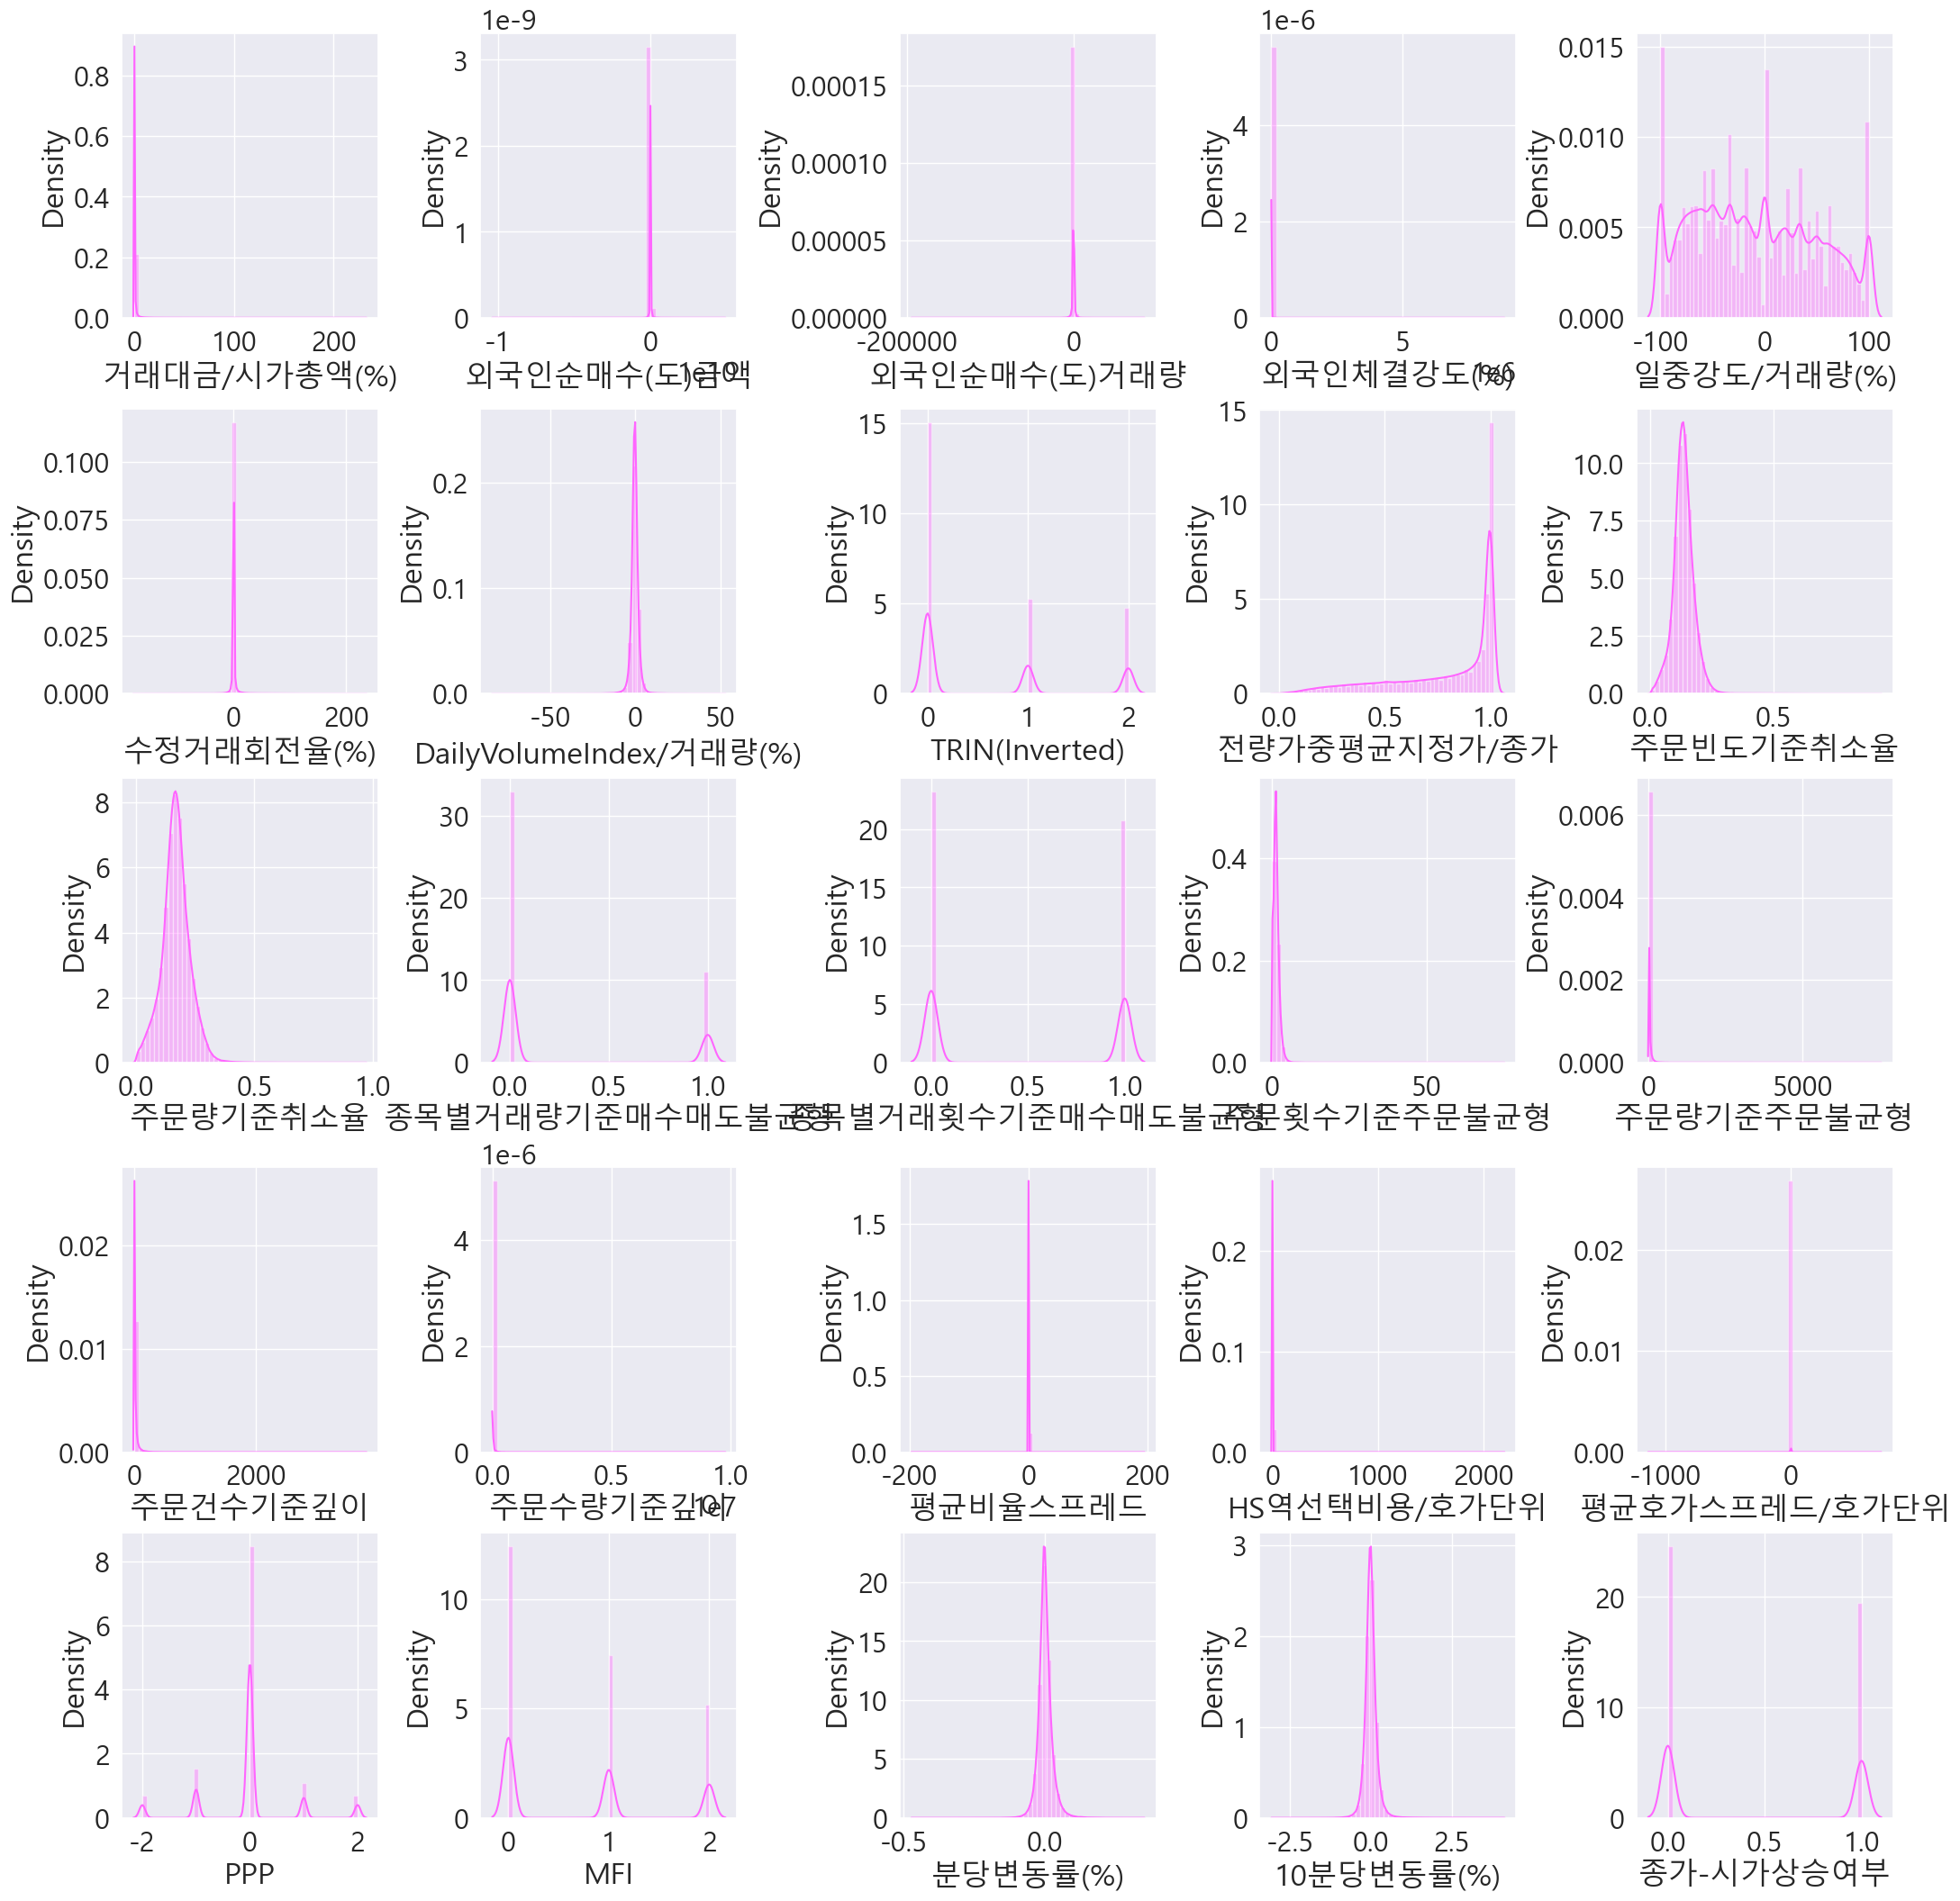

In [39]:
colors = "#FF66FF"
color_palette=["gray","#0e4f66"]
background_color = '#fafafa'
#style.use("fivethirtyeight")
plt.rcParams["figure.figsize"] = (16,16)

cols = df_final.columns.tolist()
sns.set(font="Malgun Gothic",
        rc={"axes.unicode_minus":False},
        font_scale=2)
fig, axes = plt.subplots(nrows = 5, ncols = 5, figsize = (21, 21),constrained_layout=True) # constrained layout 
for i, col_name in enumerate(cols):
  row = i // 5
  col = i % 5
  sns.distplot(df_final[col_name], ax = axes[row][col], color = colors)
  print("{}.".format(i+1),df_final.columns[i])
  print(f'{df_final.columns[i]}의 왜도 : {np.round(skew(df_final.iloc[:,i]),2)}')
  print(f'{df_final.columns[i]}의 첨도 : {np.round(kurtosis(df_final.iloc[:,i]),2)}'+"\n")

### 3.3.3 이상치 확인(Boxplot)

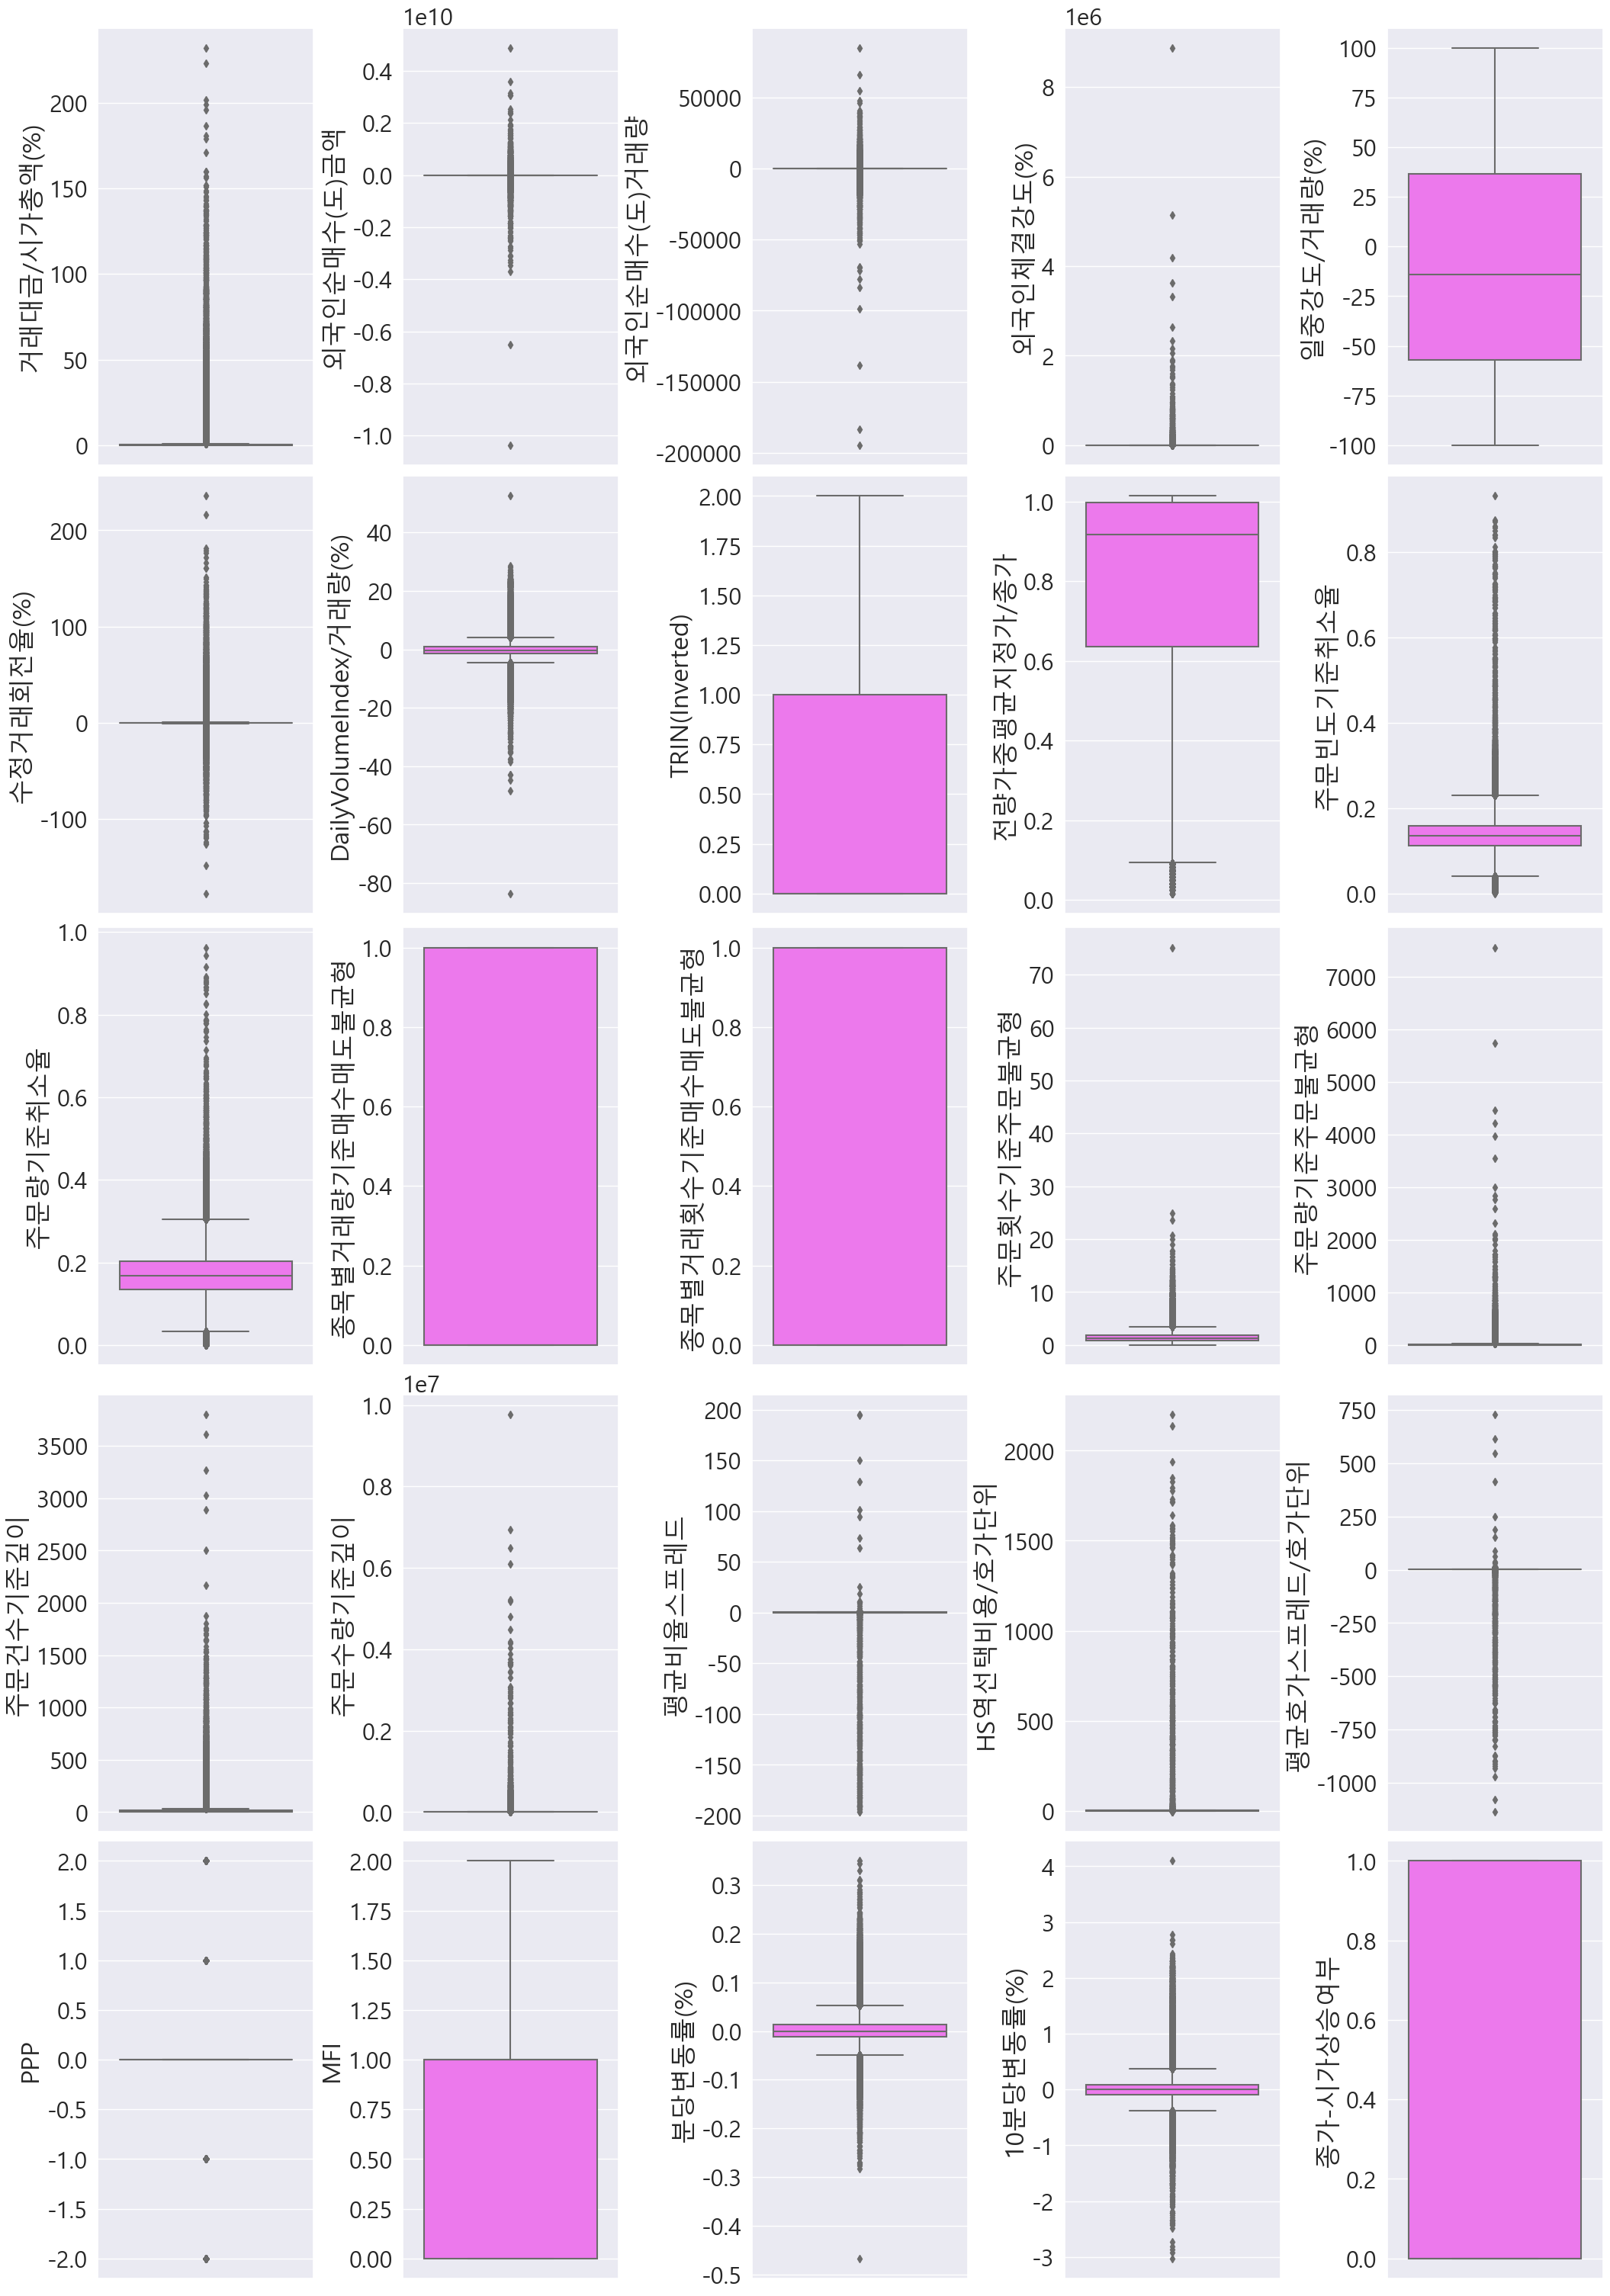

In [40]:
plt.rcParams["figure.figsize"] = (16,2)
    
fig, axes = plt.subplots(nrows = 5, ncols = 5, figsize = (21, 30),constrained_layout=True) # constrained layout 
for i, col_name in enumerate(cols):
  row = i // 5
  col = i % 5
  sns.boxplot(y=col_name, ax = axes[row][col],data=df_final,orient="v" ,color = colors)

plt.show()

### 3.3.4 이상치 처리

#### 3.3.4.1 양쪽끝단 이상치 처리 - 윈저화 1%(0.5, 0.5)

In [4]:
win_df = []
for i in range(len(df_final.columns)):
  dt = winsorize(df_final.iloc[:,i], limits=[0.005, 0.005])
  win_df.append(np.ma.getdata(dt))

df_final_win = pd.DataFrame(data=win_df, index=df_final.columns, columns=df_final.index).transpose()

In [42]:
df_final_win.describe()

,거래대금/시가총액(%),외국인순매수(도)금액,외국인순매수(도)거래량,외국인체결강도(%),일중강도/거래량(%),수정거래회전율(%),DailyVolumeIndex/거래량(%),TRIN(Inverted),전량가중평균지정가/종가,주문빈도기준취소율,...,주문건수기준깊이,주문수량기준깊이,평균비율스프레드,HS역선택비용/호가단위,평균호가스프레드/호가단위,PPP,MFI,분당변동률(%),10분당변동률(%),종가-시가상승여부
count,656583.000000,6.565830e+05,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,...,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000,656583.000000
mean,0.710855,-3.749325e+05,-22.905735,217.590820,-8.972855,0.075286,-0.273081,0.587502,0.792503,0.135820,...,15.423382,2697.502859,0.231483,0.599222,1.180283,-0.035446,0.711069,0.001913,0.002125,0.441690
std,2.386814,1.069939e+07,468.048535,633.062424,57.477695,1.956997,2.061854,0.787834,0.251543,0.040186,...,33.285800,8438.830731,0.106090,0.514994,0.495780,0.811764,0.786973,0.024494,0.179404,0.496589
min,0.003300,-7.850172e+07,-3338.000000,0.000000,-100.000000,-9.251078,-8.588957,0.000000,0.098600,0.023700,...,0.028900,1.752100,0.039600,-0.119400,0.095000,-2.000000,0.000000,-0.073939,-0.590052,0.000000
25%,0.064200,-4.606290e+05,-40.000000,43.949800,-57.142857,-0.187985,-1.333333,0.000000,0.635700,0.112100,...,1.371900,201.960750,0.153200,0.259300,0.995400,0.000000,0.000000,-0.011560,-0.096408,0.000000
50%,0.158400,-2.828000e+03,0.000000,96.754600,-14.285714,-0.034881,-0.285714,0.000000,0.916600,0.134900,...,4.719000,633.124000,0.206300,0.465700,1.074400,0.000000,1.000000,0.000012,-0.000158,0.000000
75%,0.422200,2.741825e+05,27.000000,165.147550,36.363636,0.124202,0.813008,1.000000,0.997500,0.159400,...,14.632200,1891.287200,0.291800,0.782000,1.314100,0.000000,1.000000,0.013772,0.091035,1.000000
max,24.192000,7.195428e+07,2482.000000,7000.000000,100.000000,17.737403,7.228916,2.000000,1.003700,0.258000,...,283.190100,88885.107400,0.587000,3.285100,3.791200,2.000000,2.000000,0.100524,0.760831,1.000000


#### 3.3.4.2 윈저화 후 분포도 재확인

1. 거래대금/시가총액(%)
거래대금/시가총액(%)의 왜도 : 7.39
거래대금/시가총액(%)의 첨도 : 61.9

2. 외국인순매수(도)금액
외국인순매수(도)금액의 왜도 : -0.74
외국인순매수(도)금액의 첨도 : 31.06

3. 외국인순매수(도)거래량
외국인순매수(도)거래량의 왜도 : -1.72
외국인순매수(도)거래량의 첨도 : 22.53

4. 외국인체결강도(%)
외국인체결강도(%)의 왜도 : 8.31
외국인체결강도(%)의 첨도 : 78.7

5. 일중강도/거래량(%)
일중강도/거래량(%)의 왜도 : 0.2
일중강도/거래량(%)의 첨도 : -1.03

6. 수정거래회전율(%)
수정거래회전율(%)의 왜도 : 4.48
수정거래회전율(%)의 첨도 : 44.41

7. DailyVolumeIndex/거래량(%)
DailyVolumeIndex/거래량(%)의 왜도 : -0.16
DailyVolumeIndex/거래량(%)의 첨도 : 2.63

8. TRIN(Inverted)
TRIN(Inverted)의 왜도 : 0.87
TRIN(Inverted)의 첨도 : -0.84

9. 전량가중평균지정가/종가
전량가중평균지정가/종가의 왜도 : -1.09
전량가중평균지정가/종가의 첨도 : -0.02

10. 주문빈도기준취소율
주문빈도기준취소율의 왜도 : 0.08
주문빈도기준취소율의 첨도 : 0.55

11. 주문량기준취소율
주문량기준취소율의 왜도 : 0.04
주문량기준취소율의 첨도 : 0.36

12. 종목별거래량기준매수매도불균형
종목별거래량기준매수매도불균형의 왜도 : 1.15
종목별거래량기준매수매도불균형의 첨도 : -0.68

13. 종목별거래횟수기준매수매도불균형
종목별거래횟수기준매수매도불균형의 왜도 : 0.11
종목별거래횟수기준매수매도불균형의 첨도 : -1.99

14. 주문횟수기준주문불균형
주문횟수기준주문불균형의 왜도 : 1.03
주문횟수기준주문불균형의 첨도 : 1.59

15. 주문량기준주문불균형
주문량기준주문불균형의 왜도 : 5.08
주문량기준주문불균형의 첨도 : 31

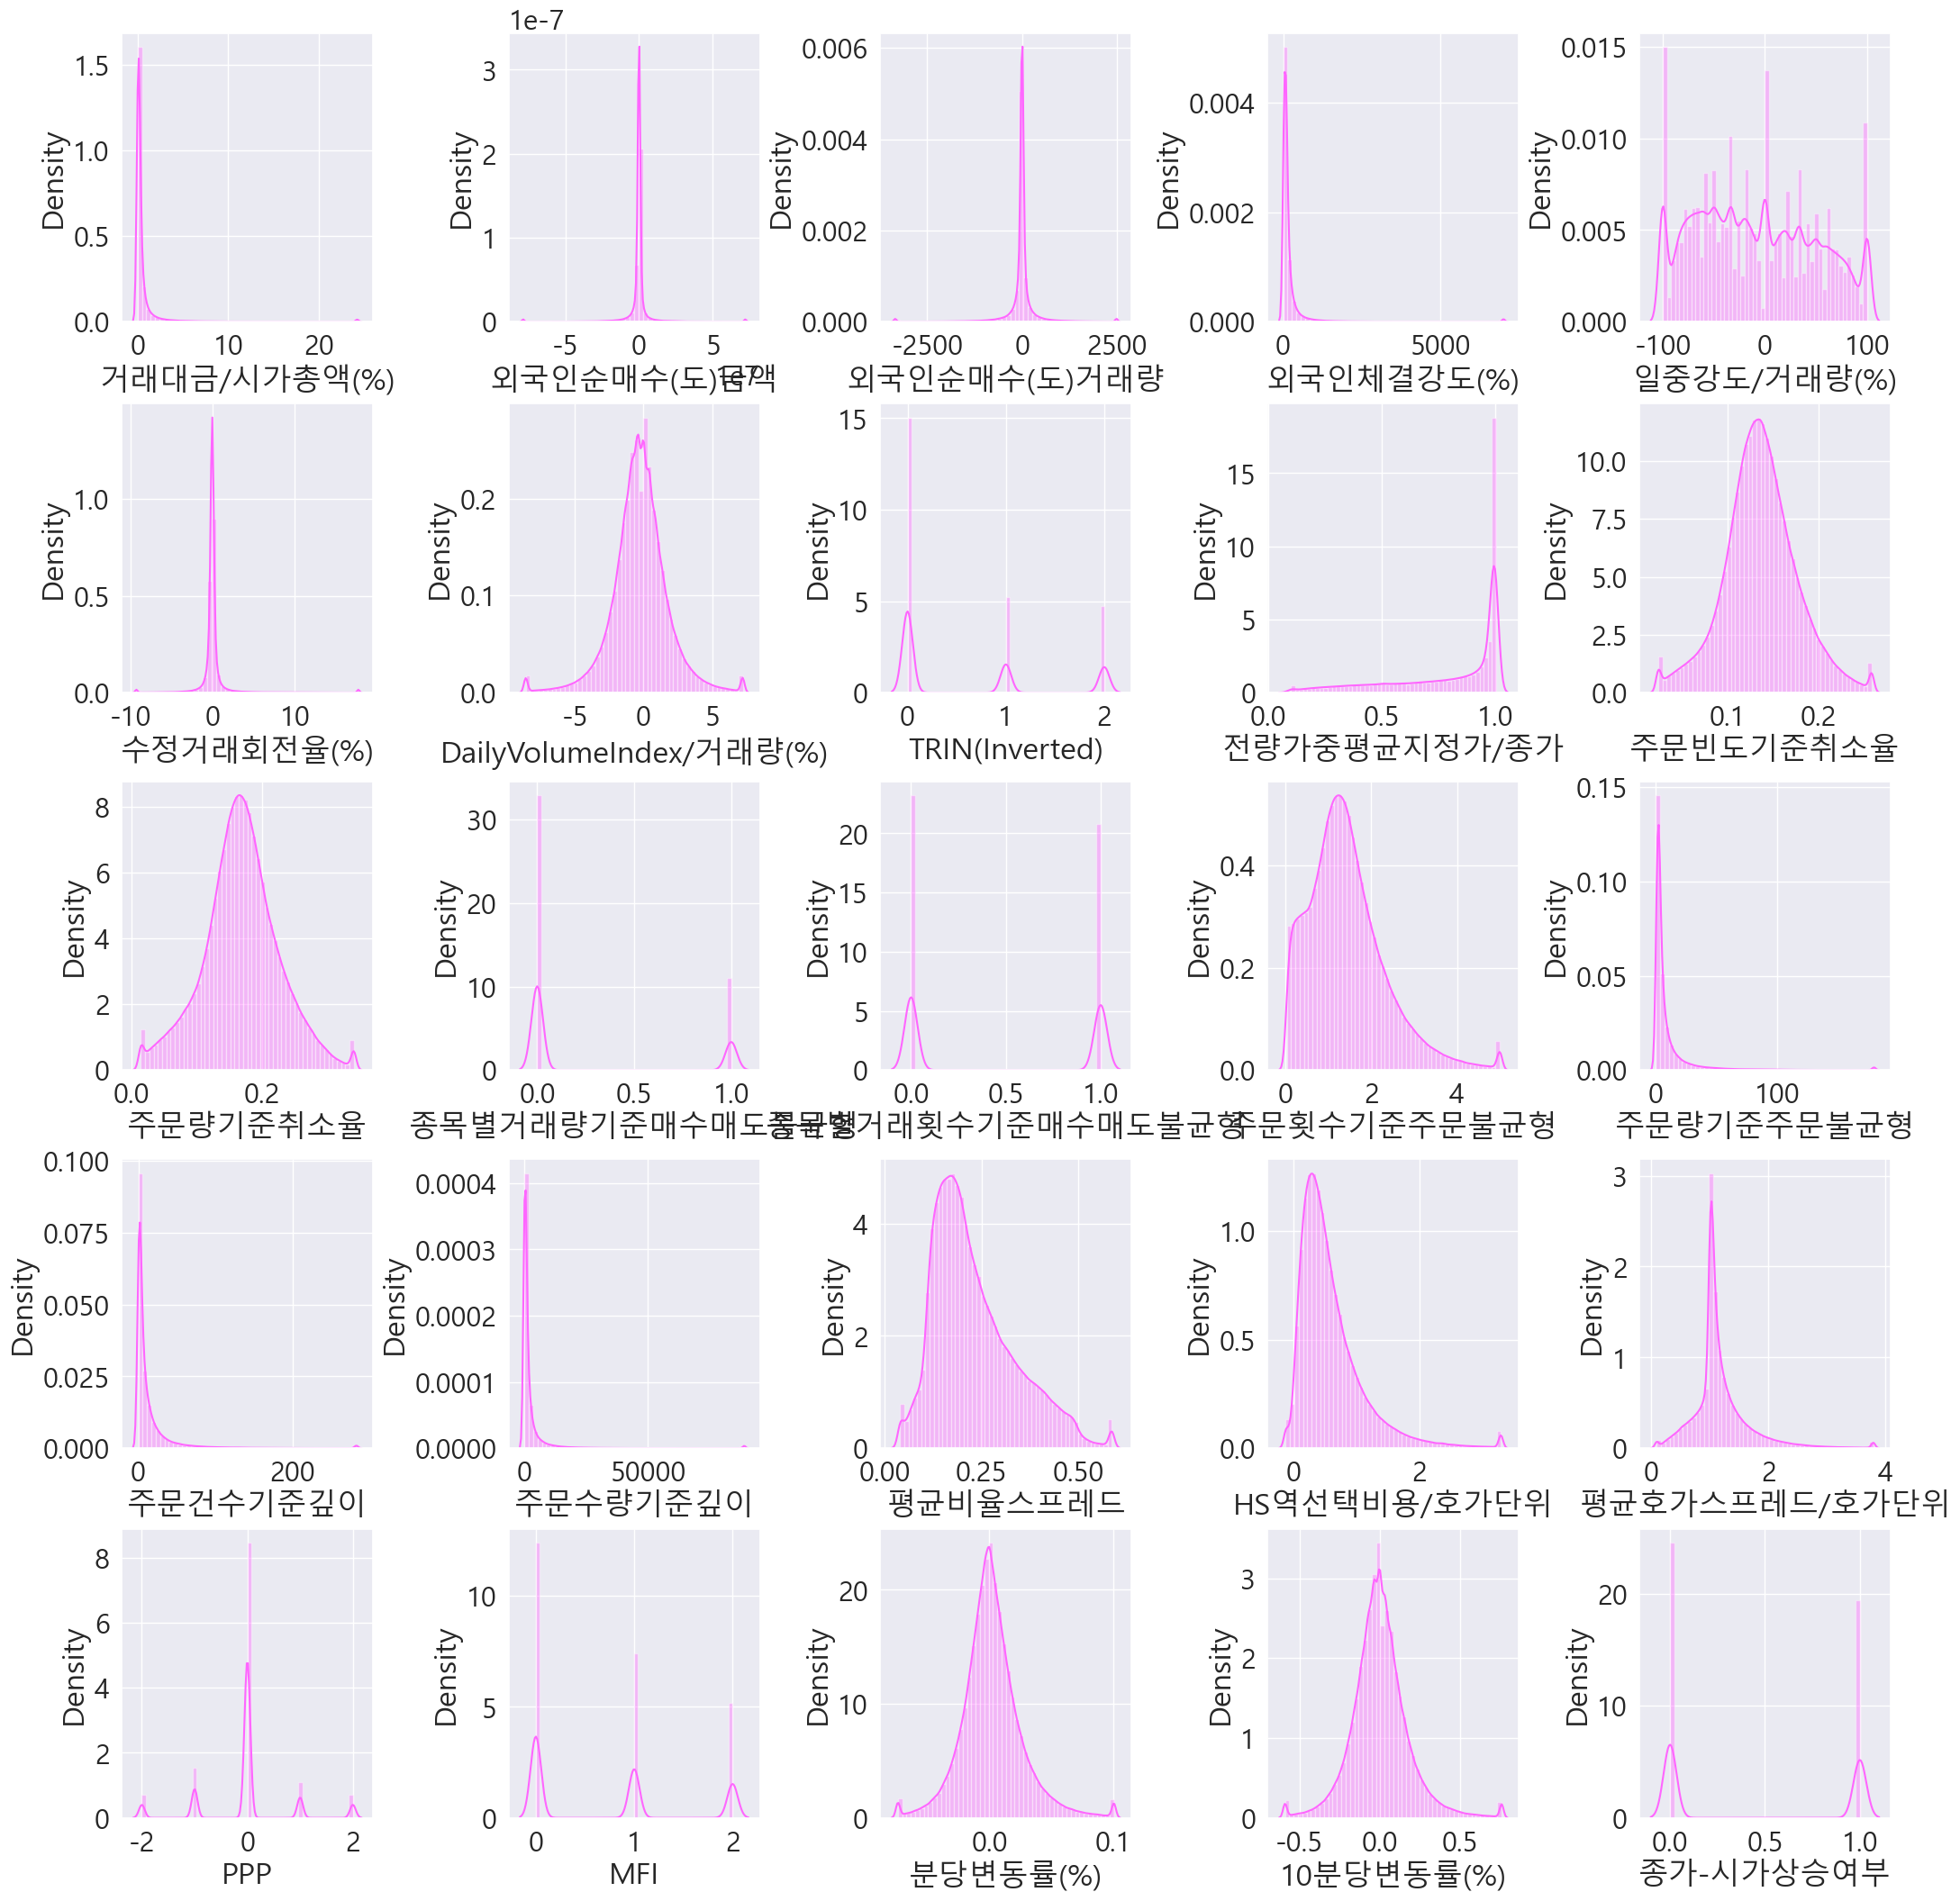

In [43]:
colors = "#FF66FF"
color_palette=["gray","#0e4f66"]
background_color = '#fafafa'
#style.use("fivethirtyeight")
plt.rcParams["figure.figsize"] = (16,16)

cols = df_final_win.columns.tolist()
sns.set(font="Malgun Gothic",
        rc={"axes.unicode_minus":False},
        font_scale=2)
fig, axes = plt.subplots(nrows = 5, ncols = 5, figsize = (21, 21),constrained_layout=True) # constrained layout 
for i, col_name in enumerate(cols):
  row = i // 5
  col = i % 5
  sns.distplot(df_final_win[col_name], ax = axes[row][col], color = colors)
  print("{}.".format(i+1),df_final_win.columns[i])
  print(f'{df_final_win.columns[i]}의 왜도 : {np.round(skew(df_final_win.iloc[:,i]),2)}')
  print(f'{df_final_win.columns[i]}의 첨도 : {np.round(kurtosis(df_final_win.iloc[:,i]),2)}'+"\n")

### 3.3.5 정규성 가정 확인

#### 3.3.5.1 시각화로 확인(Q-Q Plot)

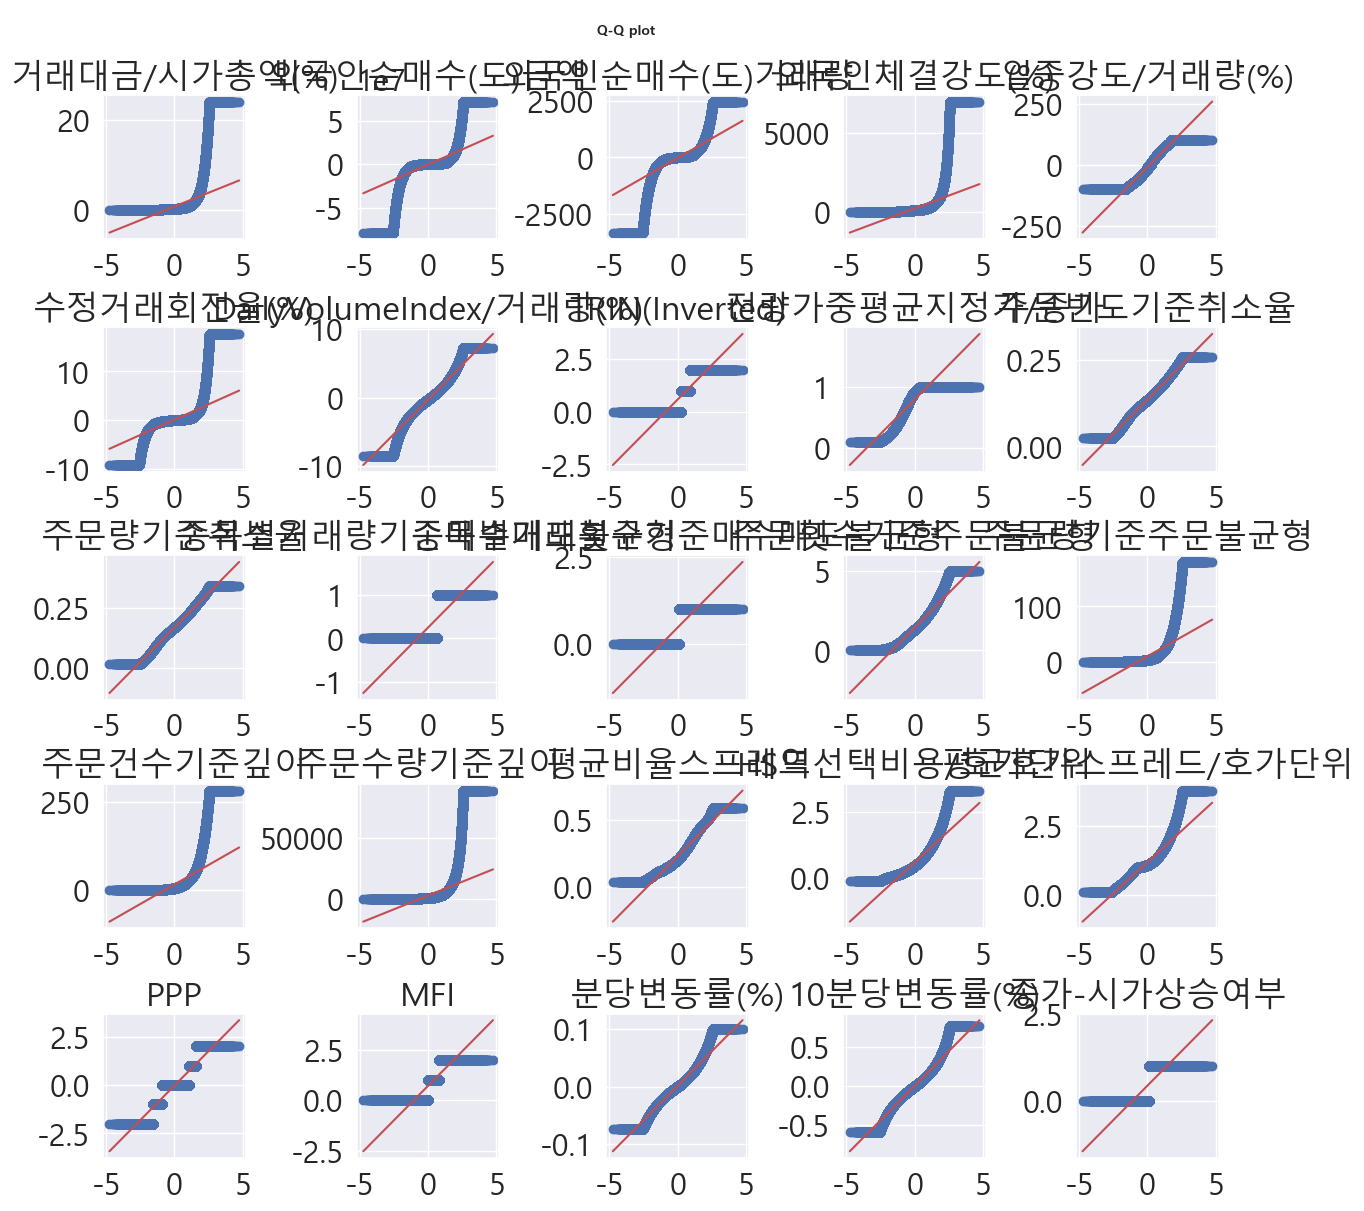

In [44]:
fig, axes = plt.subplots(nrows = 5, ncols = 5,figsize=(12, 12),constrained_layout=True)   
axes = axes.flatten()         # Convert axes to 1d array of length 9
# fig.set_size_inches(1, 15) #비율로 figsize 조정 

for ax, col in zip(axes, df_final_win.columns):
  probplot(df_final_win[col], plot = ax)
  ax.set(xlabel="", ylabel="")
  ax.set_title(col)
  fig.suptitle('\nQ-Q plot \n', fontsize=10,fontweight='bold')

#### 3.3.5.2 정규성 검정 - Anderson-Darling Test

In [45]:
print('### Anderson-Darling Test 결과 ###')
norm_yes = []
for i in df_final_win.columns:
  test_stat= anderson(df_final_win[i], dist='norm')
  print(f"{i}의 통계량 : {test_stat[0]}     95%수준 임계값 : {test_stat[1][2]}")
  if test_stat[0] < 0.787:
    norm_yes.append(test_stat)
print(f'### 95% 신뢰수준에서 정규성을 만족하는 피쳐는 {len(norm_yes)}개 입니다')

### Anderson-Darling Test 결과 ###
거래대금/시가총액(%)의 통계량 : 161493.60382301977     95%수준 임계값 : 0.787
외국인순매수(도)금액의 통계량 : 136287.27042775415     95%수준 임계값 : 0.787
외국인순매수(도)거래량의 통계량 : 101398.66208803351     95%수준 임계값 : 0.787
외국인체결강도(%)의 통계량 : 150230.42564834678     95%수준 임계값 : 0.787
일중강도/거래량(%)의 통계량 : 5961.048942349036     95%수준 임계값 : 0.787
수정거래회전율(%)의 통계량 : 123193.00759361498     95%수준 임계값 : 0.787
DailyVolumeIndex/거래량(%)의 통계량 : 5647.536773731117     95%수준 임계값 : 0.787
TRIN(Inverted)의 통계량 : 90263.82206783164     95%수준 임계값 : 0.787
전량가중평균지정가/종가의 통계량 : 48535.157908595516     95%수준 임계값 : 0.787
주문빈도기준취소율의 통계량 : 1550.1251204804284     95%수준 임계값 : 0.787
주문량기준취소율의 통계량 : 1340.4959251959808     95%수준 임계값 : 0.787
종목별거래량기준매수매도불균형의 통계량 : 157192.60069022956     95%수준 임계값 : 0.787
종목별거래횟수기준매수매도불균형의 통계량 : 118445.64606158133     95%수준 임계값 : 0.787
주문횟수기준주문불균형의 통계량 : 6930.522679881426     95%수준 임계값 : 0.787
주문량기준주문불균형의 통계량 : 117000.5099188448     95%수준 임계값 : 0.787
주문건수기준깊이의 통계량 : 109091.90925325744     95%수준 임계값 : 0.

# 4. 변수 선정

## 4.1 데이터셋 분리

### 4.1.1 features(설명변수)와 target(종속변수)로 분리 
* 분리 후 target data의 레이블 분포 확인

In [5]:
target = df_final_win['종가-시가상승여부']
features = df_final_win.drop(['종가-시가상승여부'], axis=1)
print(features.shape)
print(target.shape)
print(target.value_counts())

(656583, 24)
(656583,)
0.0    366577
1.0    290006
Name: 종가-시가상승여부, dtype: int64


종속변수인 '종가-시가상승여부' 컬럼의 비율을 통해 **Target data의 불균형이 크게 없음**을 확인할 수 있습니다.

## 4.2 유의성 검정을 통한 변수 선정

### 4.2.1 단계적 선택법(AIC기준)을 통한 변수 선정

In [6]:
variables = features.columns[:].tolist() ## 설명 변수 리스트
 
y = target ## 반응 변수
selected_variables = [] ## 선택된 변수들
sl_enter = 0.05
sl_remove = 0.05
 
sv_per_step = [] ## 각 스텝별로 선택된 변수들
# adjusted_r_squared = [] ## 각 스텝별 수정된 결정계수
aic = [] ## 각 스텝별 AIC값
steps = [] ## 스텝
step = 0
while len(variables) > 0:
    remainder = list(set(variables) - set(selected_variables))
    pval = pd.Series(index=remainder) ## 변수의 p-value
    ## 기존에 포함된 변수와 새로운 변수 하나씩 돌아가면서 
    ## 로짓 모형을 적합한다.
    for col in remainder: 
        X = features[selected_variables+[col]]
        X = sm.add_constant(X)
        model = sm.GLM(y,X, family=sm.families.Binomial()).fit()
        pval[col] = model.pvalues[col]
 
    min_pval = pval.min()
    if min_pval < sl_enter: ## 최소 p-value 값이 기준 값보다 작으면 포함
        selected_variables.append(pval.idxmin())
        ## 선택된 변수들에대해서
        ## 어떤 변수를 제거할지 고른다.
        while len(selected_variables) > 0:
            selected_X = features[selected_variables]
            selected_X = sm.add_constant(selected_X)
            selected_pval = sm.GLM(y,selected_X, family=sm.families.Binomial()).fit().pvalues[1:] ## 절편항의 p-value는 뺀다
            max_pval = selected_pval.max()
            if max_pval >= sl_remove: ## 최대 p-value값이 기준값보다 크거나 같으면 제외
                remove_variable = selected_pval.idxmax()
                selected_variables.remove(remove_variable)
            else:
                break
        
        step += 1
        steps.append(step)
        aic_ = sm.GLM(y,sm.add_constant(features[selected_variables])).fit().aic
        aic.append(aic_)
        sv_per_step.append(selected_variables.copy())
    else:
        break

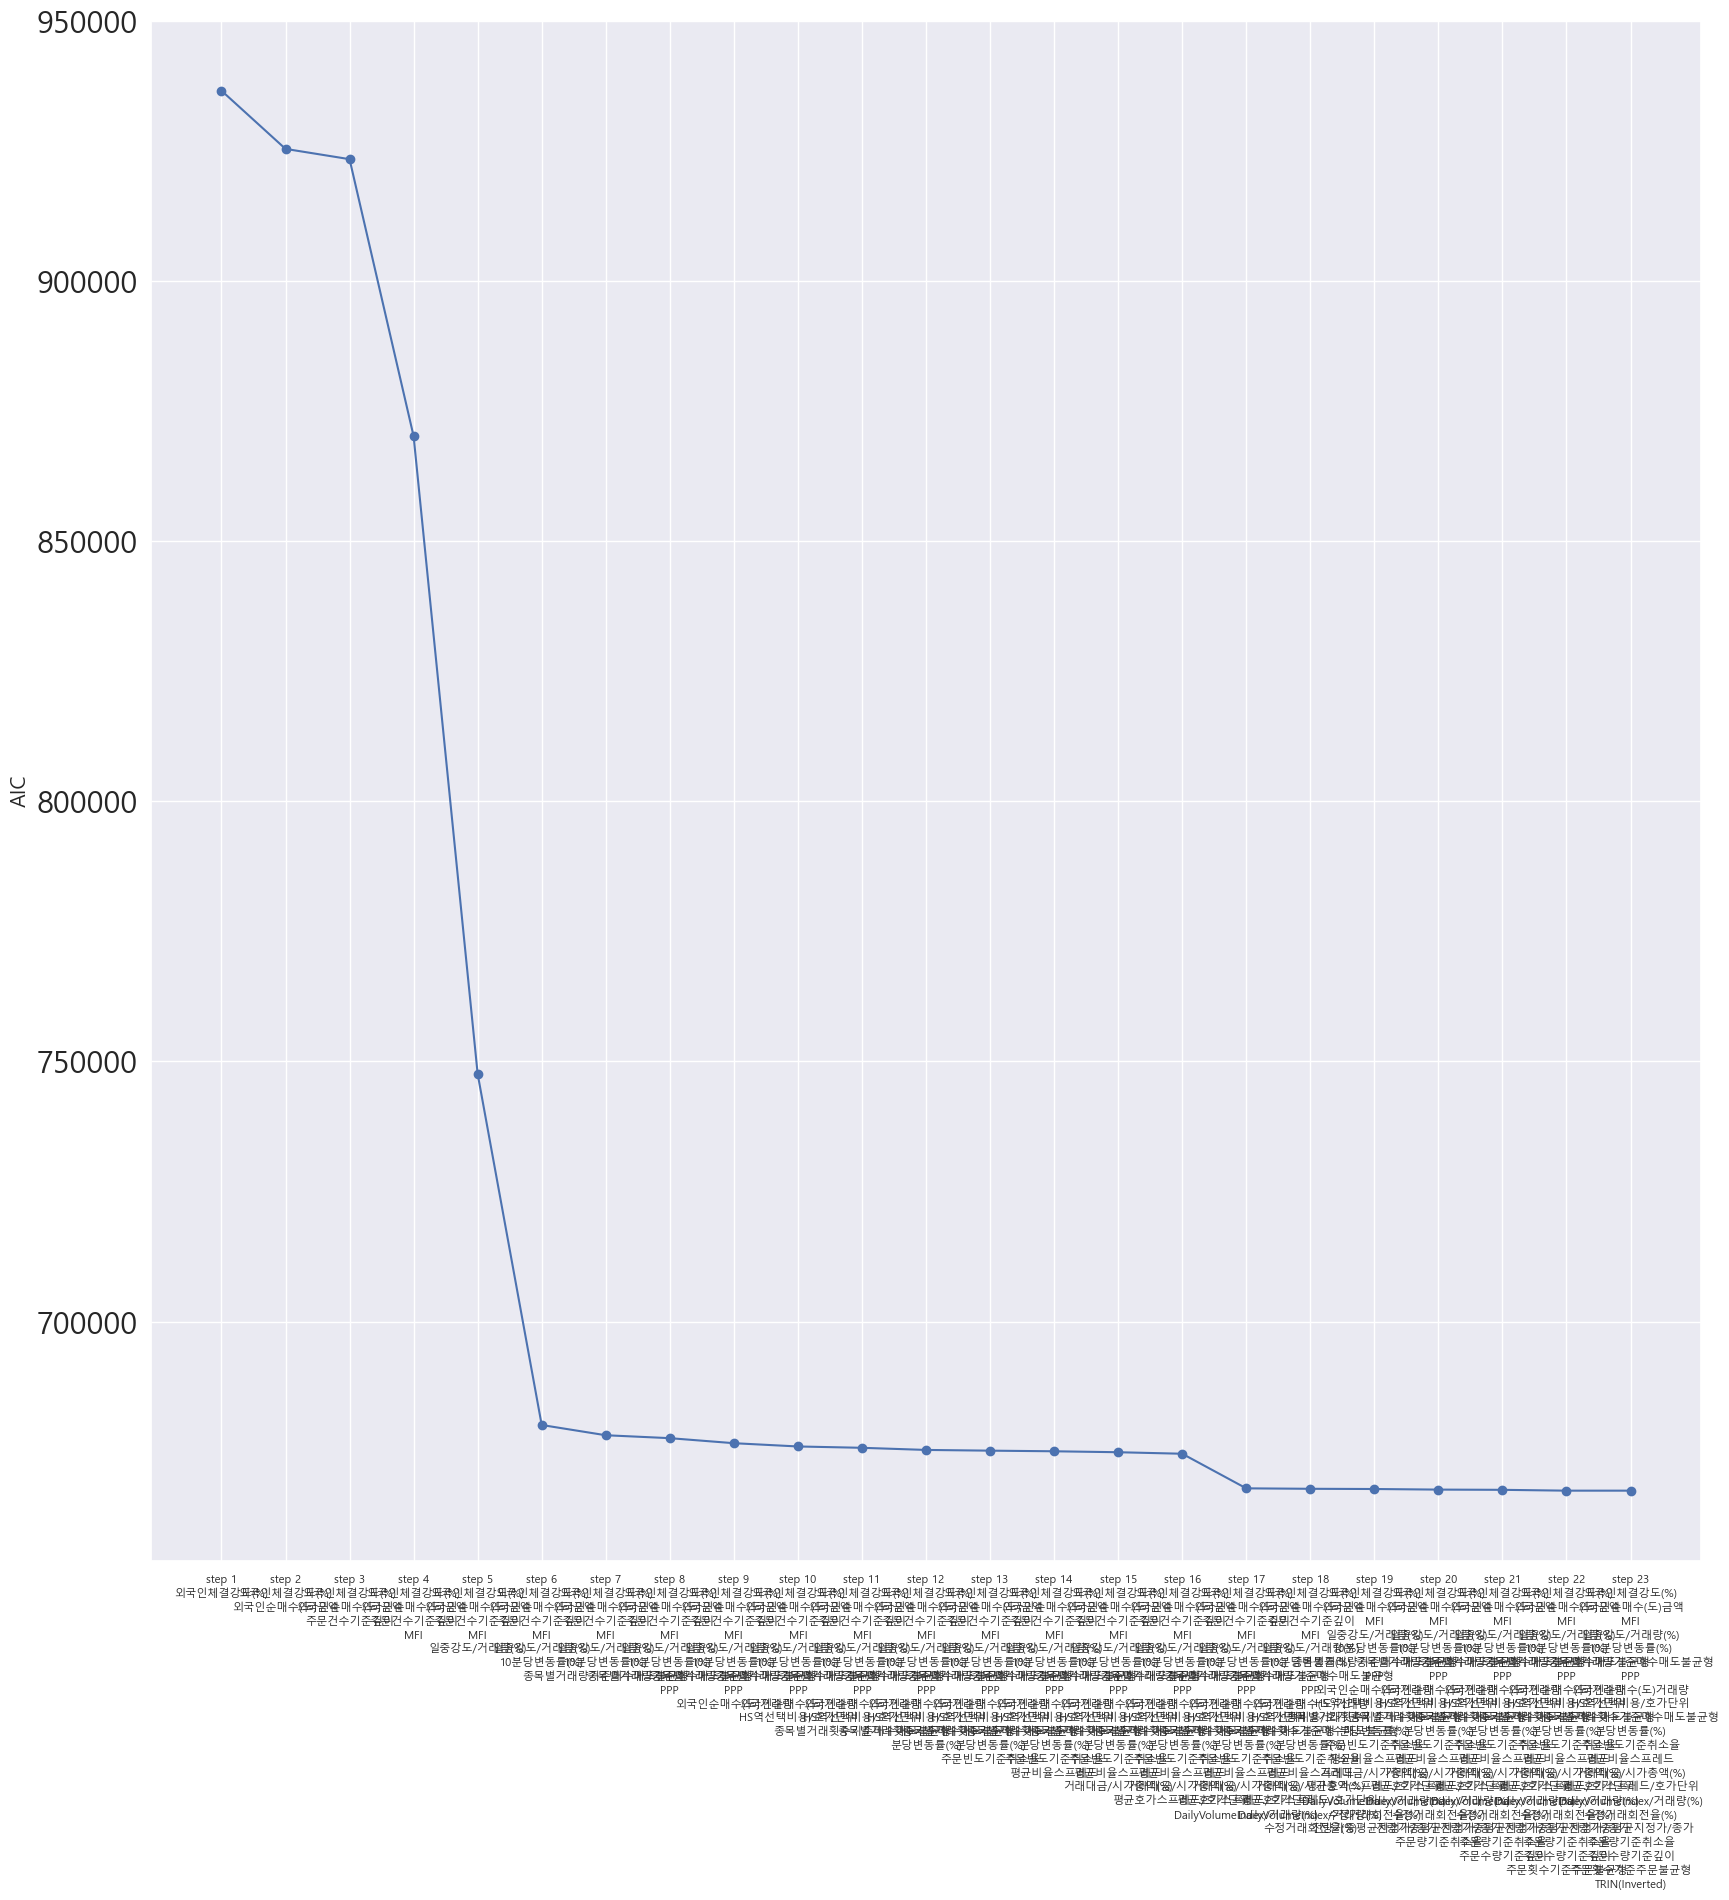

최종 AIC : [936607.8639153006, 925413.682988822, 923437.7060197401, 870190.2987672823, 747601.8330127044, 680105.5460736722, 678136.8392083171, 677574.7820517045, 676608.6026614357, 675979.2821619998, 675722.0887042279, 675313.0334249475, 675173.3829321022, 675053.8418734879, 674871.8661534374, 674581.4358994626, 667929.2098382208, 667842.618819516, 667800.7025041197, 667687.2951606212, 667643.5502362212, 667483.4001644334, 667484.5640419413]


In [7]:
fig = plt.figure(figsize=(20,20))
 
font_size = 15
sns.set(font="Malgun Gothic",
        rc={"axes.unicode_minus":False},
        font_scale=2)
plt.xticks(steps,[f'step {s}\n'+'\n'.join(sv_per_step[i]) for i,s in enumerate(steps)], fontsize=8)
plt.plot(steps,aic, marker='o')

plt.ylabel('AIC',fontsize=15)
plt.grid(True)
plt.show()
print(f'최종 AIC : {aic}')

### 4.2.2 검정 통계량 및 유의한 변수 확인
* 95% 신뢰수준, p-value < 0.05인 변수 선정

In [8]:
summary = sm.GLM(y,sm.add_constant(features[selected_variables]), family=sm.families.Binomial()).fit().summary()
print(summary)

                 Generalized Linear Model Regression Results                  
Dep. Variable:              종가-시가상승여부   No. Observations:               656583
Model:                            GLM   Df Residuals:                   656560
Model Family:                Binomial   Df Model:                           22
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -3.1293e+05
Date:                Fri, 19 Aug 2022   Deviance:                   6.2586e+05
Time:                        19:56:04   Pearson chi2:                 7.37e+05
No. Iterations:                     6   Pseudo R-squ. (CS):             0.3426
Covariance Type:            nonrobust                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [9]:
print(selected_variables)
print(len(selected_variables))

['외국인체결강도(%)', '외국인순매수(도)금액', 'MFI', '일중강도/거래량(%)', '10분당변동률(%)', '종목별거래량기준매수매도불균형', 'PPP', '외국인순매수(도)거래량', 'HS역선택비용/호가단위', '종목별거래횟수기준매수매도불균형', '분당변동률(%)', '주문빈도기준취소율', '평균비율스프레드', '거래대금/시가총액(%)', '평균호가스프레드/호가단위', 'DailyVolumeIndex/거래량(%)', '수정거래회전율(%)', '전량가중평균지정가/종가', '주문량기준취소율', '주문수량기준깊이', '주문횟수기준주문불균형', 'TRIN(Inverted)']
22


In [10]:
# 선택된 변수로 데이터셋 구성
X_final = features[selected_variables]
X_final

,,,외국인체결강도(%),외국인순매수(도)금액,MFI,일중강도/거래량(%),10분당변동률(%),종목별거래량기준매수매도불균형,PPP,외국인순매수(도)거래량,HS역선택비용/호가단위,종목별거래횟수기준매수매도불균형,...,평균비율스프레드,거래대금/시가총액(%),평균호가스프레드/호가단위,DailyVolumeIndex/거래량(%),수정거래회전율(%),전량가중평균지정가/종가,주문량기준취소율,주문수량기준깊이,주문횟수기준주문불균형,TRIN(Inverted)
거래일자,종목코드,종목명,,,,,,,,,,,,,,,,,,,,,
20190103,KR7000020008,동화약품,8.9539,-453372.0,0.0,-69.230769,-0.206874,0.0,0.0,-49.0,0.6478,0.0,...,0.1191,0.0564,1.1120,-1.962923,-0.056241,0.6695,0.1270,191.9917,0.5855,1.0
20190104,KR7000020008,동화약품,47.8099,-138998.0,0.0,-38.461538,0.200071,0.0,0.0,-15.0,0.3423,1.0,...,0.1387,0.0522,1.2476,-0.547046,0.054243,0.3381,0.0621,103.0413,0.2078,1.0
20190107,KR7000020008,동화약품,6.1050,-428775.0,1.0,44.827586,0.285324,1.0,0.0,-44.0,0.5980,1.0,...,0.2595,0.2826,2.7621,1.337449,0.277271,0.5537,0.0908,201.0868,0.5587,0.0
20190108,KR7000020008,동화약품,82.2626,-9893.0,0.0,0.000000,0.114242,0.0,0.0,-1.0,0.6762,0.0,...,0.1704,0.0196,1.6317,0.000000,-0.019673,0.3050,0.0874,37.5207,0.3577,1.0
20190109,KR7000020008,동화약품,135.8571,19766.0,1.0,-16.666667,0.261621,0.0,0.0,2.0,0.2773,0.0,...,0.1706,0.0238,1.7239,-0.209424,0.023547,0.4052,0.0930,90.2769,0.3170,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20220725,KYG5307W1015,엘브이엠씨홀딩스,58.9150,-25011.0,1.0,0.000000,0.158139,0.0,0.0,-9.0,0.1131,1.0,...,0.1747,0.0302,1.0423,0.000000,0.030576,0.6199,0.1310,625.8554,0.9844,0.0
20220726,KYG5307W1015,엘브이엠씨홀딩스,185.0285,50704.0,1.0,14.285714,-0.056385,1.0,0.0,17.0,0.3734,1.0,...,0.1625,0.0283,0.9909,0.169779,0.028567,0.6098,0.2188,510.9835,1.1019,0.0
20220727,KYG5307W1015,엘브이엠씨홀딩스,92.2605,-4097.0,0.0,45.454545,0.013946,0.0,0.0,-1.0,0.3128,1.0,...,0.1427,0.0441,0.8618,0.847458,-0.043946,0.5446,0.1602,407.1529,1.1414,0.0


### 4.2.3 변수간 상관관계 확인

<AxesSubplot:>

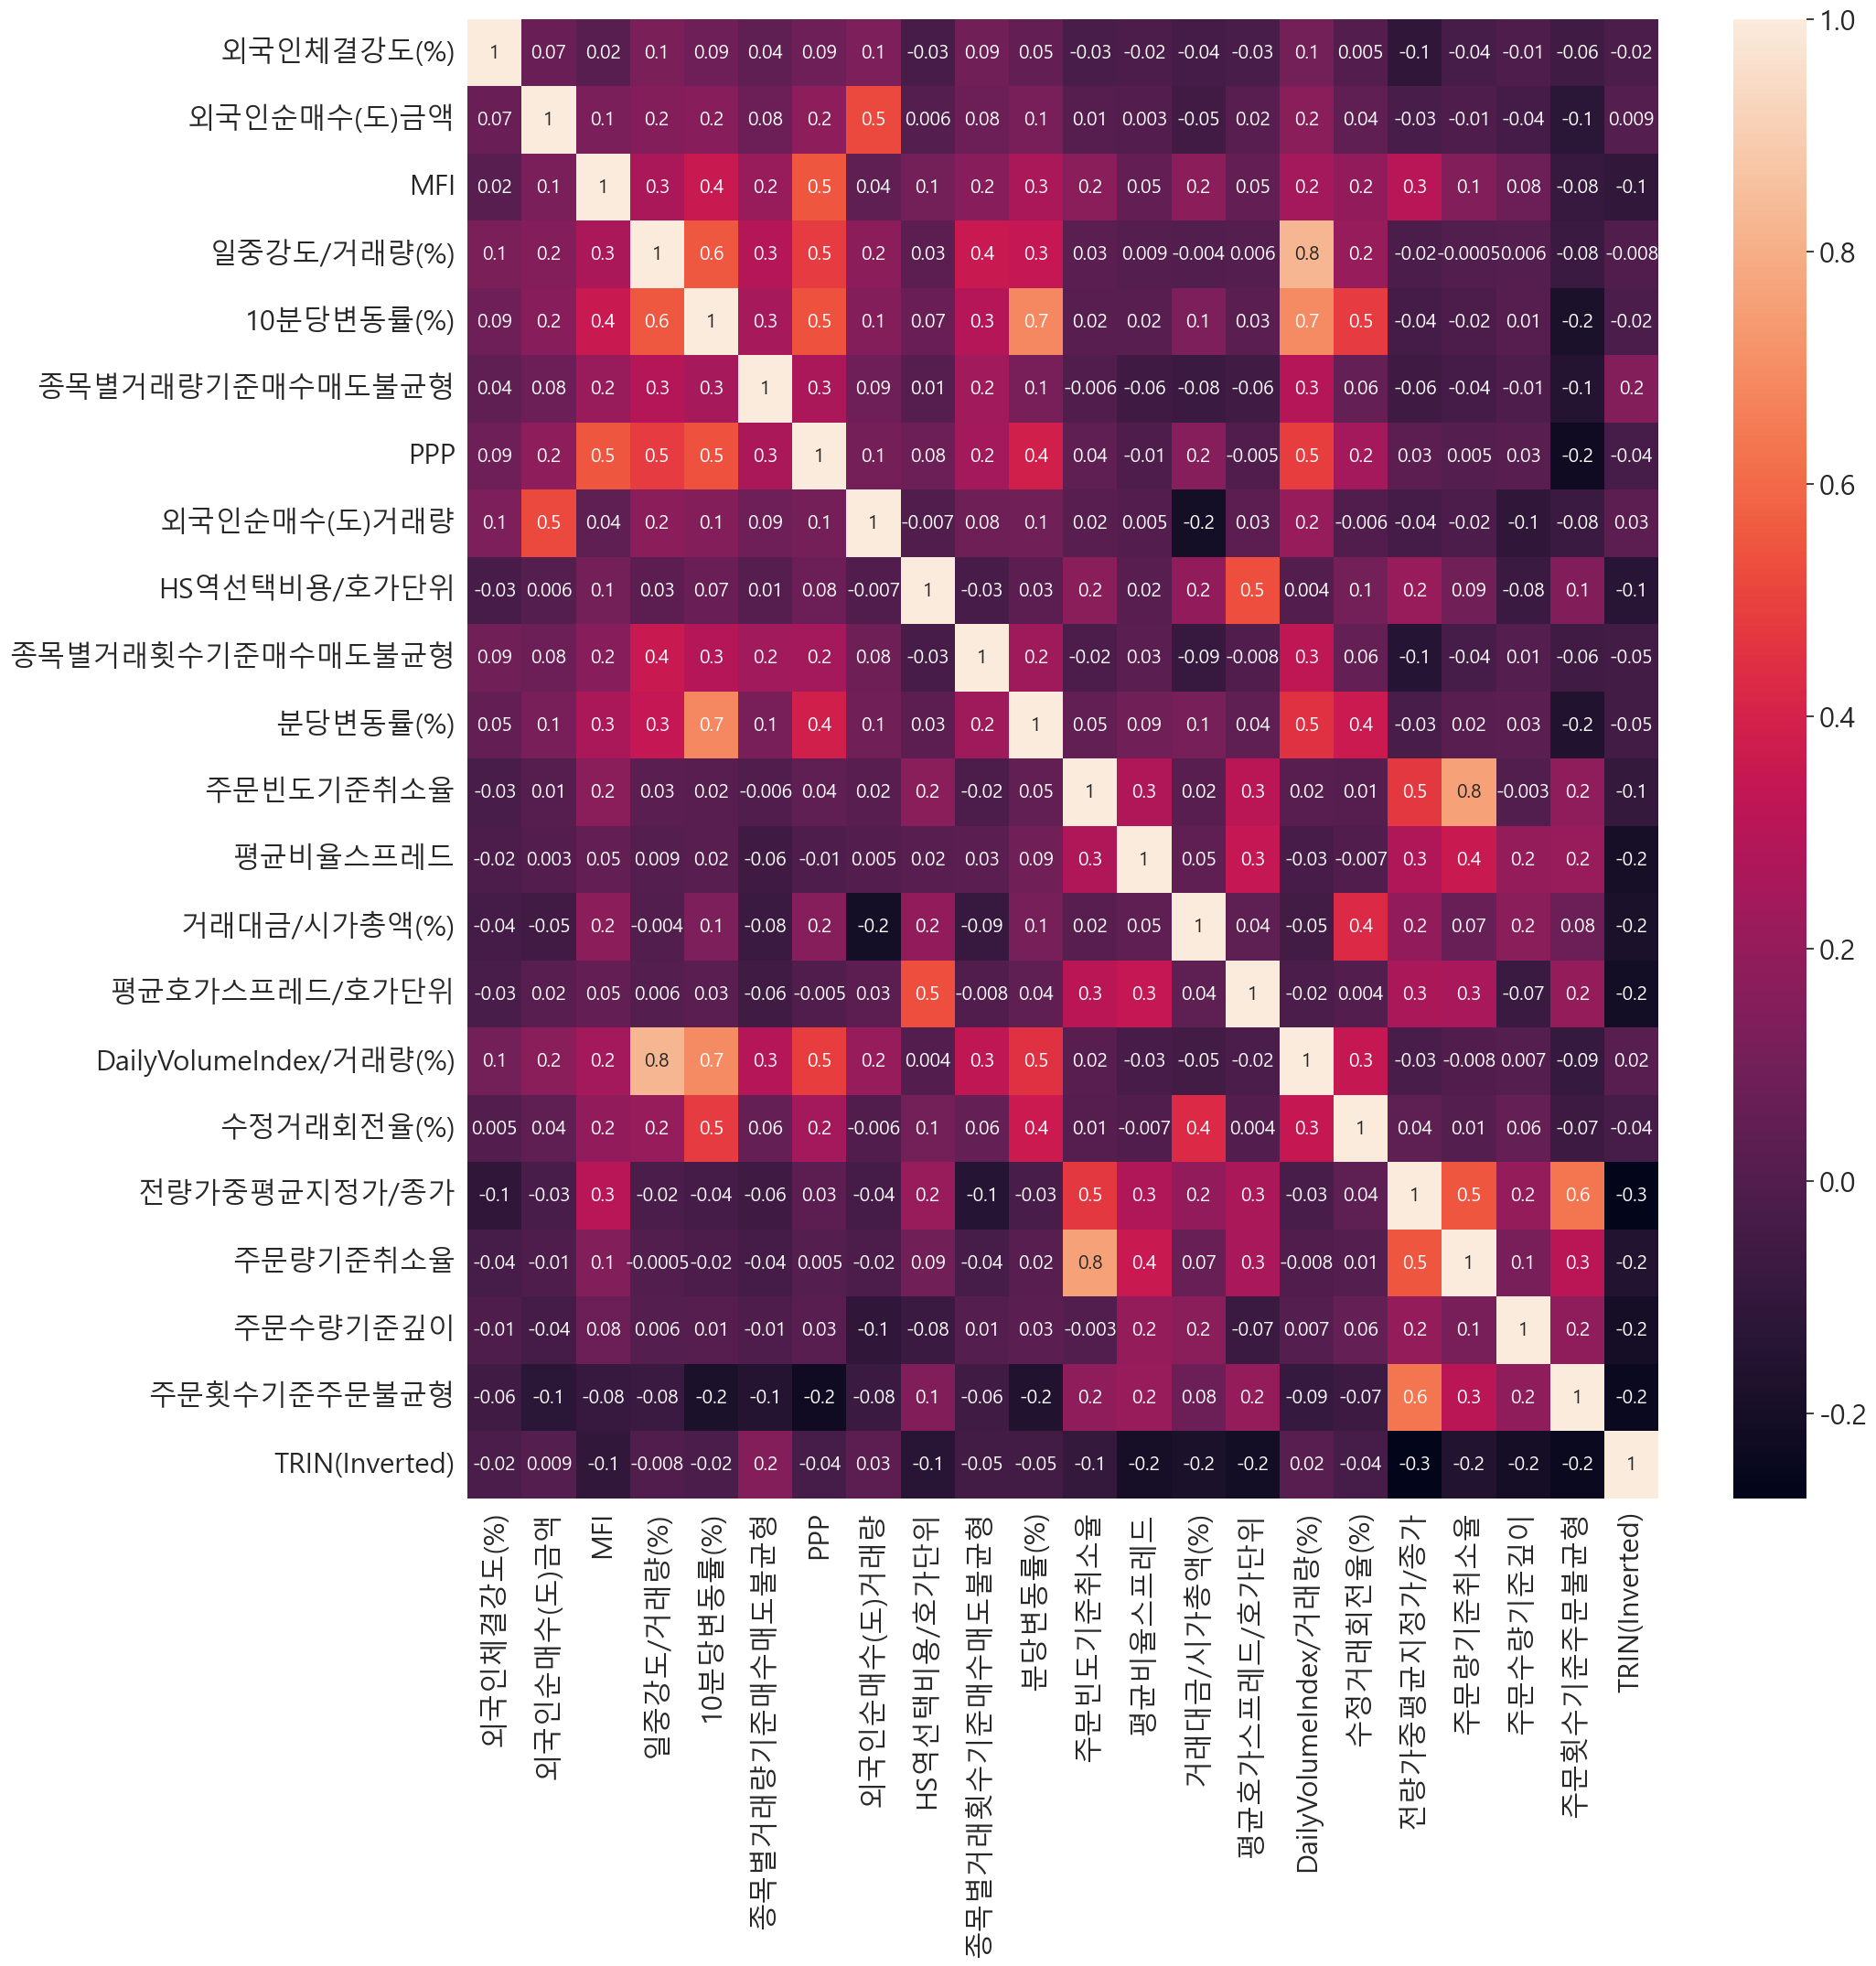

In [11]:
# 상관계수 히트맵
corr_X_final = X_final.corr()
plt.figure(figsize=(21,21))
sns.heatmap(corr_X_final, annot=True, fmt='.1g', annot_kws={"size": 15})

### 4.2.4 VIF 지수 확인(다중공선성)

In [12]:
# VIF 지수로 다중공선성 확인
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = []
df_val = X_final.values

for i in range(len(X_final.columns)):
  vif.append(np.round(variance_inflation_factor(df_val, i),2))

vif_df = pd.DataFrame()
vif_df['features'] = X_final.columns
vif_df['VIF'] = vif
vif_df

,features,VIF
0,외국인체결강도(%),1.15
1,외국인순매수(도)금액,1.41
2,MFI,3.34
3,일중강도/거래량(%),3.61
4,10분당변동률(%),3.42
5,종목별거래량기준매수매도불균형,1.62
6,PPP,2.01
7,외국인순매수(도)거래량,1.49
8,HS역선택비용/호가단위,3.70
9,종목별거래횟수기준매수매도불균형,2.22


상관계수와 VIF 지수가 높은 변수들이 다소 있지만 
1) 95% 신뢰수준에서 모두 유의한 변수들이며,
2) 회귀가 아닌 분류분석의 특성상 정확한 다중공선성 측정이 쉽지 않고,
3) 예측력의 최대화를 목표로 하기 위해서

변수를 추가적으로 축소하지 않기로 하였습니다.

# 5. 모델링

## 5.1 훈련/검증 데이터 분리

### 5.1.1 Train:Test 7:3 분리
* 평가를 위해 샘플은 random_state=9로 고정

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X_final, target, test_size=0.3, random_state=9, shuffle=True)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(459608, 22) (459608,)
(196975, 22) (196975,)


### 5.1.2 Target data 비율 확인

In [14]:
print(y_train.value_counts())
print(y_test.value_counts())

0.0    256638
1.0    202970
Name: 종가-시가상승여부, dtype: int64
0.0    109939
1.0     87036
Name: 종가-시가상승여부, dtype: int64


## 5.2 예측 및 평가

### 5.2.1 로지스틱회귀

#### 5.2.1.1 로지스틱회귀 예측 및 결과 평가

In [53]:
lg_clf = LogisticRegression(C=0.8, penalty='l1', random_state=9, solver='liblinear')
lg_clf.fit(X_train,y_train)
y_pred = lg_clf.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('### Logistic Regression 분류 결과 ###')
print(f'ACC : {acc_score:.4f}')
print(f'Precision : {precision:.4f}')
print(f'Recall : {recall:.4f}')
print(f'F1 Score : {f1:.4f}')

### Logistic Regression 분류 결과 ###
ACC : 0.7716
Precision : 0.7599
Recall : 0.7061
F1 Score : 0.7320
                               외국인순매수(도)금액  수정거래회전율(%)  외국인체결강도(%)  \
거래일자     종목코드         종목명                                            
20191025 KR7005500004 삼진제약        -24574.0    0.030360     80.4636   
20220426 KR7005880000 대한해운      -1826994.0   -0.158834     24.2411   
20220525 KR7005070008 코스모신소재   -10100726.0   -1.380060     69.9240   
20200605 KR7016090003 대현         -646679.0   -0.550175     24.8250   
20210907 KR7001630003 종근당홀딩스     -110832.0   -0.046009     67.3469   
...                                    ...         ...         ...   
20210302 KR7088980008 맥쿼리인프라     1044202.0   -0.060872    991.8110   
20210818 KR7008560005 메리츠증권      3936358.0   -0.078289    183.3582   
20220415 KR7229640008 LS전선아시아    -764604.0   -0.527551     62.9318   
20200715 KR7081660003 휠라홀딩스     11743550.0    0.383813    165.9491   
20200731 KR7145270005 케이탑리츠        -2645.0   -0.030069      

#### 5.2.1.2 로지스틱회귀 계수 값 확인(로그오즈 값)

10분당변동률(%)          9.063039
주문빈도기준취소율           1.725391
PPP                 0.489582
종목별거래량기준매수매도불균형     0.380037
MFI                 0.169361
전량가중평균지정가/종가        0.161483
평균호가스프레드/호가단위       0.041157
주문횟수기준주문불균형         0.027774
종목별거래횟수기준매수매도불균형    0.027540
HS역선택비용/호가단위        0.014955
수정거래회전율(%)          0.008218
외국인순매수(도)거래량        0.000244
주문건수기준깊이            0.000198
주문량기준주문불균형          0.000121
외국인체결강도(%)          0.000001
DailyVolumeIndex   -0.000000
외국인순매수(도)금액        -0.000000
일중강도                0.000000
주문수량기준깊이           -0.000002
TRIN(Inverted)     -0.012867
평균비율스프레드           -0.035008
거래대금/시가총액(%)       -0.041354
주문량기준취소율           -0.898130
분당변동률(%)           -5.141161
dtype: float64


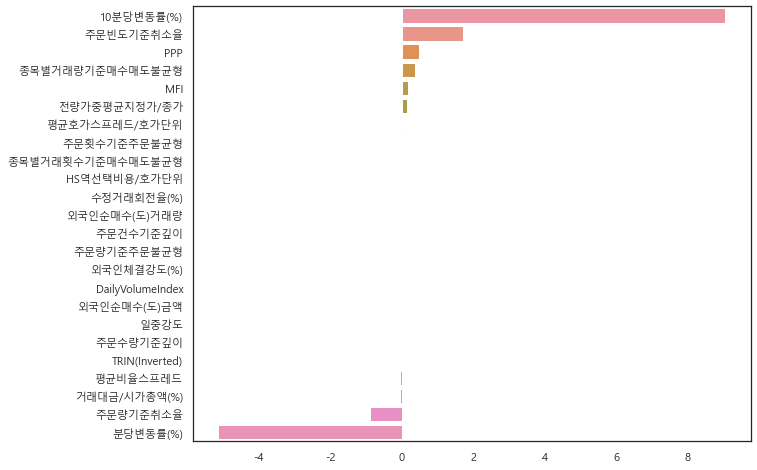

In [13]:
plt.rcParams["figure.figsize"] = (10,8)
feature_series = pd.Series(data = np.round(lg_clf.coef_[0],6), index=X_train.columns)
feature_series = feature_series.sort_values(ascending=False)
sns.barplot(x=feature_series, y=feature_series.index)
print(feature_series)

### 5.2.2 의사결정나무 분류분석

#### 5.2.2.1 의사결정나무 예측 및 결과 평가

In [58]:
dt_clf = DecisionTreeClassifier(random_state=9, max_depth=7, max_features='auto', min_samples_split=4)
dt_clf.fit(X_train,y_train)
y_pred = dt_clf.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('### Decision classifier 분류 결과 ###')
print(f'ACC : {acc_score:.4f}')
print(f'Precision : {precision:.4f}')
print(f'Recall : {recall:.4f}')
print(f'F1 Score : {f1:.4f}')

### Decision classifier 분류 결과 ###
ACC : 0.7929
Precision : 0.7845
Recall : 0.7326
F1 Score : 0.7577


### 5.2.3 RandomForest 분류분석

#### 5.2.3.1 RandomForest 예측 및 결과 평가

In [59]:
rf_clf = RandomForestClassifier(random_state=9, max_depth=5, n_estimators=100, min_samples_split=4)
rf_clf.fit(X_train,y_train)
y_pred = rf_clf.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('### RF classifier 분류 결과 ###')
print(f'ACC : {acc_score:.4f}')
print(f'Precision : {precision:.4f}')
print(f'Recall : {recall:.4f}')
print(f'F1 Score : {f1:.4f}')

### RF classifier 분류 결과 ###
ACC : 0.8001
Precision : 0.7929
Recall : 0.7411
F1 Score : 0.7661


#### 5.2.3.2 RandomForest 모델의 각 변수 중요도 확인

수정거래회전율(%)                 0.308893
10분당변동률(%)                 0.260909
일중강도/거래량(%)                0.137213
DailyVolumeIndex/거래량(%)    0.094402
PPP                        0.074120
분당변동률(%)                   0.043245
MFI                        0.020620
외국인체결강도(%)                 0.015497
외국인순매수(도)금액                0.014420
외국인순매수(도)거래량               0.012257
종목별거래량기준매수매도불균형            0.008906
주문횟수기준주문불균형                0.002656
종목별거래횟수기준매수매도불균형           0.002401
전량가중평균지정가/종가               0.001308
거래대금/시가총액(%)               0.001161
HS역선택비용/호가단위               0.001154
평균호가스프레드/호가단위              0.000387
주문빈도기준취소율                  0.000281
주문수량기준깊이                   0.000092
평균비율스프레드                   0.000040
주문량기준취소율                   0.000033
TRIN(Inverted)             0.000006
dtype: float64


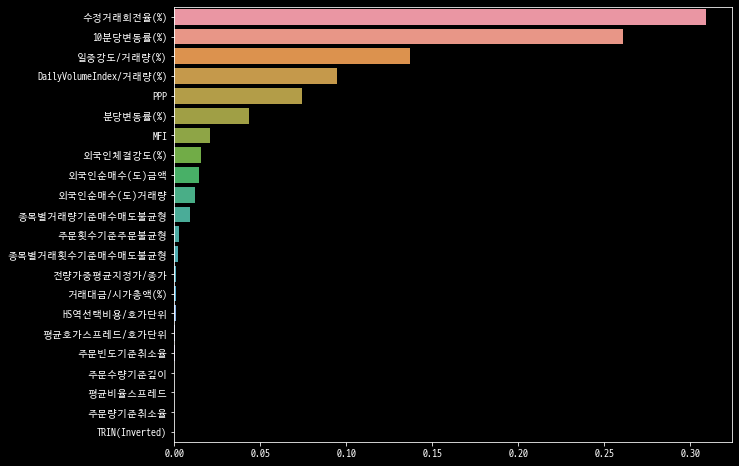

In [60]:
feature_series = pd.Series(data = rf_clf.feature_importances_, index=X_train.columns)
feature_series = feature_series.sort_values(ascending=False)
sns.barplot(x=feature_series, y=feature_series.index)
print(feature_series)

### 5.2.4 XGBoost 분류분석

#### 5.2.4.1 XGBoost 예측 및 결과 평가

In [61]:
xgb_clf = XGBClassifier(random_state=9, n_estimators=100, max_depth=7, eval_metric='logloss')
xgb_clf.fit(X_train,y_train)
y_pred = xgb_clf.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('### XGB classifier 분류 결과 ###')
print(f'ACC : {acc_score:.4f}')
print(f'Precision : {precision:.4f}')
print(f'Recall : {recall:.4f}')
print(f'F1 Score : {f1:.4f}')

### XGB classifier 분류 결과 ###
ACC : 0.8251
Precision : 0.8174
Recall : 0.7779
F1 Score : 0.7971


#### 5.2.4.2 XGBoost 모델의 각 변수 중요도 확인

수정거래회전율(%)                 0.394505
10분당변동률(%)                 0.129853
PPP                        0.089128
거래대금/시가총액(%)               0.066116
종목별거래량기준매수매도불균형            0.042127
DailyVolumeIndex/거래량(%)    0.030176
MFI                        0.028975
외국인체결강도(%)                 0.021977
외국인순매수(도)금액                0.020950
종목별거래횟수기준매수매도불균형           0.019562
일중강도/거래량(%)                0.018094
외국인순매수(도)거래량               0.016254
전량가중평균지정가/종가               0.016034
평균비율스프레드                   0.014824
HS역선택비용/호가단위               0.012460
주문수량기준깊이                   0.011992
분당변동률(%)                   0.011929
주문횟수기준주문불균형                0.011426
주문량기준취소율                   0.011124
평균호가스프레드/호가단위              0.010917
TRIN(Inverted)             0.010798
주문빈도기준취소율                  0.010782
dtype: float32


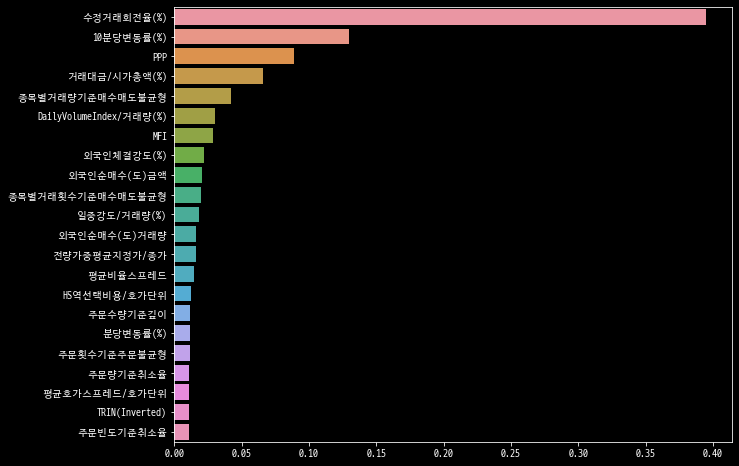

In [62]:
feature_series = pd.Series(data = xgb_clf.feature_importances_, index=X_train.columns)
feature_series = feature_series.sort_values(ascending=False)
sns.barplot(x=feature_series, y=feature_series.index)
print(feature_series)

### 5.2.5 CatBoost 분류분석

#### 5.2.5.1 CatBoost 예측 및 결과 평가

In [63]:
cat_clf = CatBoostClassifier(random_state=9, verbose=False)
cat_clf.fit(X_train, y_train)
y_pred = cat_clf.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('### Catboost classifier 분류 결과 ###')
print(f'ACC : {acc_score:.4f}')
print(f'Precision : {precision:.4f}')
print(f'Recall : {recall:.4f}')
print(f'F1 Score : {f1:.4f}')

### Catboost classifier 분류 결과 ###
ACC : 0.8296
Precision : 0.8198
Recall : 0.7875
F1 Score : 0.8033


#### 5.2.5.2 CatBoost 모델의 각 변수 중요도 확인

수정거래회전율(%)                 44.398188
거래대금/시가총액(%)               28.471996
10분당변동률(%)                  9.972185
PPP                         1.902394
DailyVolumeIndex/거래량(%)     1.851043
일중강도/거래량(%)                 1.720124
외국인체결강도(%)                  1.490459
전량가중평균지정가/종가                1.241223
외국인순매수(도)금액                 1.110010
평균비율스프레드                    1.109971
외국인순매수(도)거래량                0.809962
HS역선택비용/호가단위                0.742903
분당변동률(%)                    0.741977
MFI                         0.703855
주문수량기준깊이                    0.699692
평균호가스프레드/호가단위               0.629982
주문빈도기준취소율                   0.538165
주문량기준취소율                    0.536948
주문횟수기준주문불균형                 0.535893
종목별거래량기준매수매도불균형             0.433384
종목별거래횟수기준매수매도불균형            0.258511
TRIN(Inverted)              0.101135
dtype: float64


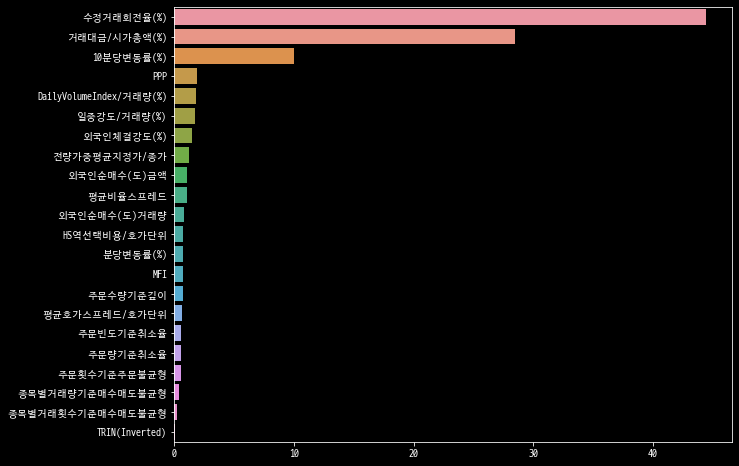

In [64]:
feature_series = pd.Series(data = cat_clf.feature_importances_, index=X_train.columns)
feature_series = feature_series.sort_values(ascending=False)
sns.barplot(x=feature_series, y=feature_series.index)
print(feature_series)

### 5.2.6 Deep Neural Network(DNN)

#### 5.2.6.1 MinMaxScaling

In [ ]:
scaler = MinMaxScaler()

scaler.fit(X_train)
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X_final.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_final.columns)

X_train_scaled

,거래대금/시가총액(%),외국인순매수(도)금액,외국인순매수(도)거래량,외국인체결강도(%),일중강도,수정거래회전율(%),DailyVolumeIndex,TRIN(Inverted),전량가중평균지정가/종가,주문빈도기준취소율,...,종목별거래횟수기준매수매도불균형,주문횟수기준주문불균형,주문수량기준깊이,평균비율스프레드,HS역선택비용/호가단위,평균호가스프레드/호가단위,PPP,MFI,분당변동률(%),10분당변동률(%)
0,0.002414,0.521759,0.573540,0.014286,0.527332,0.340500,0.558970,1.0,0.976246,0.469910,...,1.0,0.586808,0.182337,0.151443,0.070319,0.272442,0.50,0.0,0.303871,0.396001
1,0.035438,0.519292,0.538144,0.006425,0.565551,0.311079,0.551128,1.0,0.874931,0.500640,...,0.0,0.382026,0.024082,0.649068,0.195565,0.384530,0.25,0.0,0.357594,0.253384
2,0.009083,0.542946,0.578694,0.017185,0.579228,0.334308,0.563243,0.5,0.993481,0.721724,...,0.0,0.294976,0.013742,0.797223,0.143898,0.248390,0.50,0.0,0.559504,0.407220
3,0.013994,0.526188,0.619244,0.070630,0.584222,0.355455,0.564483,1.0,0.903878,0.460094,...,1.0,0.314457,0.016975,0.538729,0.024526,0.432038,0.50,0.5,0.650405,0.510804
4,0.015040,0.509360,0.553608,0.005829,0.589972,0.355936,0.566562,1.0,0.993039,0.504481,...,0.0,0.470083,0.014320,0.544026,0.175532,0.273010,0.50,0.0,0.422503,0.475355
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459603,0.001893,0.521663,0.573196,0.008309,0.578870,0.344619,0.563092,0.5,0.065186,0.062313,...,1.0,0.033140,0.000101,0.332115,0.125452,0.390753,0.50,0.0,0.362371,0.524006
459604,0.031238,1.000000,1.000000,0.096599,1.000000,0.371390,1.000000,1.0,0.997569,0.504055,...,1.0,0.198880,0.426490,0.394593,0.447496,0.245685,1.00,1.0,0.696628,0.741903
459605,0.002381,0.517690,0.571649,0.004109,0.578589,0.340549,0.563043,0.0,0.912164,0.283397,...,0.0,0.192897,0.000684,0.429302,0.224703,0.426871,0.25,0.0,0.432917,0.250912
459606,0.001430,0.521759,0.573540,0.014286,0.564678,0.341384,0.558402,1.0,0.992266,0.372172,...,1.0,0.751400,0.046698,0.555718,0.170980,0.250798,0.50,0.0,0.266762,0.273145


#### 5.2.6.2 DNN 예측 및 결과 평가

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 5096)              117208    
 dense_1 (Dense)             (None, 5096)              25974312  
 dense_2 (Dense)             (None, 1)                 5097      
Total params: 26,096,617
Trainable params: 26,096,617
Non-trainable params: 0
_________________________________________________________________
Epoch 59: early stopping
## DNN Node 5096-5096, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.46064043045043945
- Test ACC : 0.7861911654472351
- F1 score: 0.7448859058776495


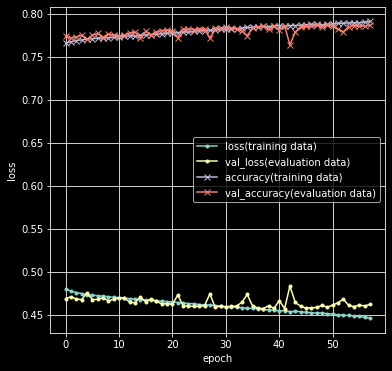

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 2048)              47104     
 dense_4 (Dense)             (None, 2048)              4196352   
 dense_5 (Dense)             (None, 1)                 2049      
Total params: 4,245,505
Trainable params: 4,245,505
Non-trainable params: 0
_________________________________________________________________
Epoch 59: early stopping
## DNN Node 2048-2048, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.4591856002807617
- Test ACC : 0.7865617275238037
- F1 score: 0.7500475624256838


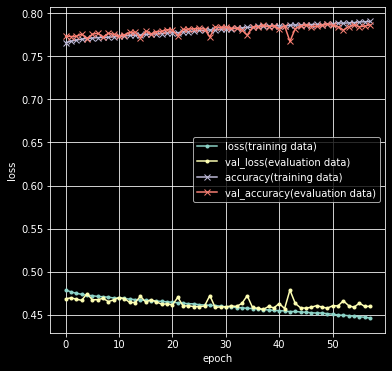

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_6 (Dense)             (None, 1024)              23552     
 dense_7 (Dense)             (None, 1024)              1049600   
 dense_8 (Dense)             (None, 1)                 1025      
Total params: 1,074,177
Trainable params: 1,074,177
Non-trainable params: 0
_________________________________________________________________
Epoch 67: early stopping
## DNN Node 1024-1024, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.4608008563518524
- Test ACC : 0.7871506810188293
- F1 score: 0.7516114507796579


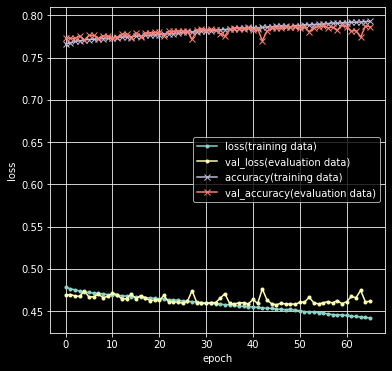

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_9 (Dense)             (None, 512)               11776     
 dense_10 (Dense)            (None, 512)               262656    
 dense_11 (Dense)            (None, 1)                 513       
Total params: 274,945
Trainable params: 274,945
Non-trainable params: 0
_________________________________________________________________
Epoch 69: early stopping
## DNN Node 512-512, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.4595869183540344
- Test ACC : 0.7879527807235718
- F1 score: 0.7457697270713121


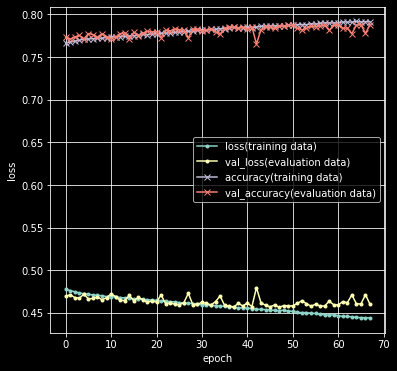

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_12 (Dense)            (None, 256)               5888      
 dense_13 (Dense)            (None, 256)               65792     
 dense_14 (Dense)            (None, 1)                 257       
Total params: 71,937
Trainable params: 71,937
Non-trainable params: 0
_________________________________________________________________
Epoch 71: early stopping
## DNN Node 256-256, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.4889092445373535
- Test ACC : 0.7639598846435547
- F1 score: 0.7540962797634788


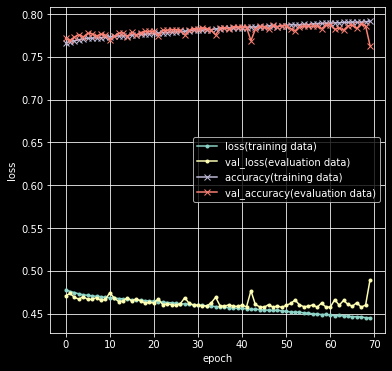

In [ ]:
callback = [EarlyStopping(monitor='val_loss', patience=20, verbose=1), ModelCheckpoint(filepath='best_model.h5', monitor='val_loss', save_best_only=True)]
tf.random.set_seed(9)

for i in [5096, 2048, 1024, 512, 256]:
        model = Sequential()
        model.add(Dense(i,input_shape = (len(X_train.columns),),activation='relu'))
        model.add(Dense(i,activation='relu'))
        model.add(Dense(1,activation='sigmoid'))

        model.summary()

        model.compile(loss='binary_crossentropy',
                    optimizer='adam',
                    metrics=['accuracy',
                    tf.keras.metrics.Precision(name='precision'),
                    tf.keras.metrics.Recall(name='recall')])
        
        hist = model.fit(X_train_scaled, y_train,
                        batch_size=200,
                        epochs=100,
                        verbose=1,
                        validation_split=0.1,
                        callbacks=callback)
        score = model.evaluate(X_test_scaled, y_test, verbose=0)

        dnn = model.predict(X_test_scaled)
        dnn = pd.DataFrame(data=dnn).astype('float64')
        dnn[0]=dnn[0].apply(lambda x: 1 if x >= 0.5 else 0)
        # print(model.evaluate(X_test_scaled, y_test))
        f1 = f1_score(y_test, dnn)

        print(f'## DNN Node {i}-{i}, 활성화 함수 relu의 결과 ##')
        print(f'- Test LOSS : {score[0]}')
        print(f'- Test ACC : {score[1]}')
        print('- F1 score:',f1)
        
        loss = hist.history['loss'][1:]
        val_loss = hist.history['val_loss'][1:]
        accu = hist.history['accuracy'][1:]
        val_accu = hist.history['val_accuracy'][1:]
        epochs = len(loss)
        plt.rcParams["figure.figsize"] = (6,6)
        plt.plot(range(epochs), loss, marker='.', label='loss(training data)')
        plt.plot(range(epochs), val_loss, marker='.', label='val_loss(evaluation data)')
        plt.plot(range(epochs), accu, marker='x', label='accuracy(training data)')
        plt.plot(range(epochs), val_accu, marker='x', label='val_accuracy(evaluation data)')
        plt.legend(loc='best')
        plt.grid()
        plt.xlabel('epoch')
        plt.ylabel('loss')
        plt.show()


Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_21 (Dense)            (None, 256)               5888      
 dense_22 (Dense)            (None, 256)               65792     
 dense_23 (Dense)            (None, 1)                 257       
Total params: 71,937
Trainable params: 71,937
Non-trainable params: 0
_________________________________________________________________
Epoch 55: early stopping
## DNN Node 256-256, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.4560452997684479
- Test ACC : 0.7851453423500061
- F1 score: 0.7436225185221084


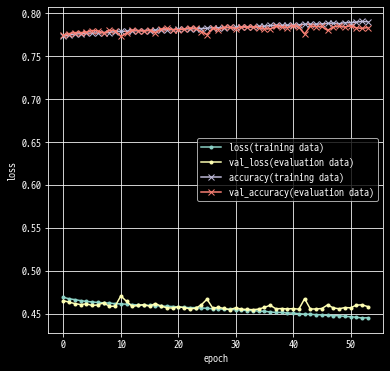

Model: "sequential_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_24 (Dense)            (None, 128)               2944      
 dense_25 (Dense)            (None, 128)               16512     
 dense_26 (Dense)            (None, 1)                 129       
Total params: 19,585
Trainable params: 19,585
Non-trainable params: 0
_________________________________________________________________
Epoch 89: early stopping
## DNN Node 128-128, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.45169597864151
- Test ACC : 0.7898514866828918
- F1 score: 0.7556751779579983


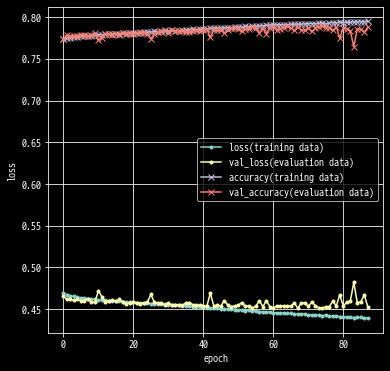

In [ ]:
callback = [EarlyStopping(monitor='val_loss', patience=20, verbose=1), ModelCheckpoint(filepath='best_model.h5', monitor='val_loss', save_best_only=True)]
tf.random.set_seed(9)

for i in [256, 128]:
        model = Sequential()
        model.add(Dense(i,input_shape = (len(X_train.columns),),activation='relu'))
        model.add(Dense(i,activation='relu'))
        model.add(Dense(1,activation='sigmoid'))

        model.summary()

        model.compile(loss='binary_crossentropy',
                    optimizer='adam',
                    metrics=['accuracy',
                    tf.keras.metrics.Precision(name='precision'),
                    tf.keras.metrics.Recall(name='recall')])
        
        hist = model.fit(X_train_scaled, y_train,
                        batch_size=200,
                        epochs=100,
                        verbose=1,
                        validation_split=0.1,
                        callbacks=callback)
        score = model.evaluate(X_test_scaled, y_test, verbose=0)

        dnn = model.predict(X_test_scaled)
        dnn = pd.DataFrame(data=dnn).astype('float64')
        dnn[0]=dnn[0].apply(lambda x: 1 if x >= 0.5 else 0)
        # print(model.evaluate(X_test_scaled, y_test))
        f1 = f1_score(y_test, dnn)

        print(f'## DNN Node {i}-{i}, 활성화 함수 relu의 결과 ##')
        print(f'- Test LOSS : {score[0]}')
        print(f'- Test ACC : {score[1]}')
        print('- F1 score:',f1)
        
        loss = hist.history['loss'][1:]
        val_loss = hist.history['val_loss'][1:]
        accu = hist.history['accuracy'][1:]
        val_accu = hist.history['val_accuracy'][1:]
        epochs = len(loss)
        plt.rcParams["figure.figsize"] = (6,6)
        plt.plot(range(epochs), loss, marker='.', label='loss(training data)')
        plt.plot(range(epochs), val_loss, marker='.', label='val_loss(evaluation data)')
        plt.plot(range(epochs), accu, marker='x', label='accuracy(training data)')
        plt.plot(range(epochs), val_accu, marker='x', label='val_accuracy(evaluation data)')
        plt.legend(loc='best')
        plt.grid()
        plt.xlabel('epoch')
        plt.ylabel('loss')
        plt.show()


Model: "sequential_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_27 (Dense)            (None, 64)                1472      
 dense_28 (Dense)            (None, 64)                4160      
 dense_29 (Dense)            (None, 1)                 65        
Total params: 5,697
Trainable params: 5,697
Non-trainable params: 0
_________________________________________________________________
## DNN Node 64-64, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.44534555077552795
- Test ACC : 0.7934661507606506
- F1 score: 0.7623242933760209


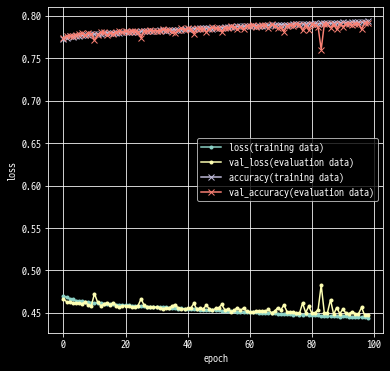

Model: "sequential_10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_30 (Dense)            (None, 32)                736       
 dense_31 (Dense)            (None, 32)                1056      
 dense_32 (Dense)            (None, 1)                 33        
Total params: 1,825
Trainable params: 1,825
Non-trainable params: 0
_________________________________________________________________
## DNN Node 32-32, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.45016199350357056
- Test ACC : 0.7893742918968201
- F1 score: 0.756660058418478


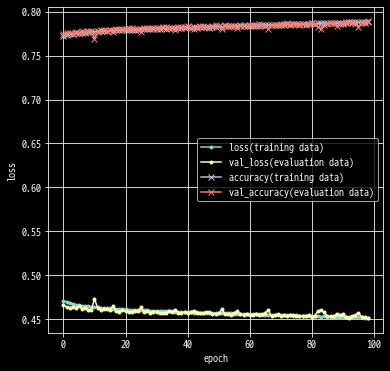

Model: "sequential_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_33 (Dense)            (None, 16)                368       
 dense_34 (Dense)            (None, 16)                272       
 dense_35 (Dense)            (None, 1)                 17        
Total params: 657
Trainable params: 657
Non-trainable params: 0
_________________________________________________________________
## DNN Node 16-16, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.44995298981666565
- Test ACC : 0.789653480052948
- F1 score: 0.7570410766118392


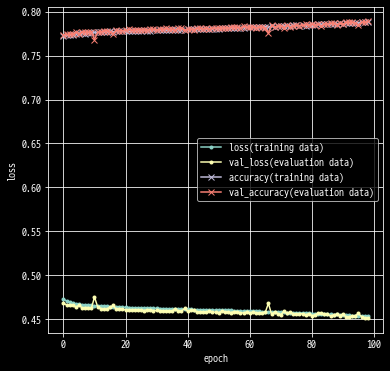

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_36 (Dense)            (None, 8)                 184       
 dense_37 (Dense)            (None, 8)                 72        
 dense_38 (Dense)            (None, 1)                 9         
Total params: 265
Trainable params: 265
Non-trainable params: 0
_________________________________________________________________
## DNN Node 8-8, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.4520343542098999
- Test ACC : 0.7883589267730713
- F1 score: 0.7550444807445971


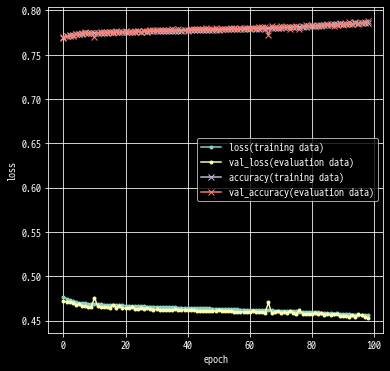

In [ ]:
callback = [EarlyStopping(monitor='val_loss', patience=20, verbose=1), ModelCheckpoint(filepath='best_model.h5', monitor='val_loss', save_best_only=True)]
tf.random.set_seed(9)

for i in [64, 32, 16, 8]:
        model = Sequential()
        model.add(Dense(i,input_shape = (len(X_train.columns),),activation='relu'))
        model.add(Dense(i,activation='relu'))
        model.add(Dense(1,activation='sigmoid'))

        model.summary()

        model.compile(loss='binary_crossentropy',
                    optimizer='adam',
                    metrics=['accuracy',
                    tf.keras.metrics.Precision(name='precision'),
                    tf.keras.metrics.Recall(name='recall')])
        
        hist = model.fit(X_train_scaled, y_train,
                        batch_size=200,
                        epochs=100,
                        verbose=1,
                        validation_split=0.1,
                        callbacks=callback)
        score = model.evaluate(X_test_scaled, y_test, verbose=0)

        dnn = model.predict(X_test_scaled)
        dnn = pd.DataFrame(data=dnn).astype('float64')
        dnn[0]=dnn[0].apply(lambda x: 1 if x >= 0.5 else 0)
        # print(model.evaluate(X_test_scaled, y_test))
        f1 = f1_score(y_test, dnn)

        print(f'## DNN Node {i}-{i}, 활성화 함수 relu의 결과 ##')
        print(f'- Test LOSS : {score[0]}')
        print(f'- Test ACC : {score[1]}')
        print('- F1 score:',f1)
        
        loss = hist.history['loss'][1:]
        val_loss = hist.history['val_loss'][1:]
        accu = hist.history['accuracy'][1:]
        val_accu = hist.history['val_accuracy'][1:]
        epochs = len(loss)
        plt.rcParams["figure.figsize"] = (6,6)
        plt.plot(range(epochs), loss, marker='.', label='loss(training data)')
        plt.plot(range(epochs), val_loss, marker='.', label='val_loss(evaluation data)')
        plt.plot(range(epochs), accu, marker='x', label='accuracy(training data)')
        plt.plot(range(epochs), val_accu, marker='x', label='val_accuracy(evaluation data)')
        plt.legend(loc='best')
        plt.grid()
        plt.xlabel('epoch')
        plt.ylabel('loss')
        plt.show()


## 5.3 강건성 검증

### 5.3.1 데이터
* 동일 기간 데이터 사용, 전처리 없이 독립변수/종속변수 분류

In [15]:
tar = pd.DataFrame(df_final[['종가-시가상승여부']])
feat = df_final.drop(['종가-시가상승여부'], axis=1)
print(tar.shape)
print(feat.shape)

(656583, 1)
(656583, 24)


### 5.3.2 훈련/검증 데이터 분리

In [16]:
X_train, X_test, y_train, y_test = train_test_split(feat, tar, test_size=0.3, random_state=20, shuffle=True)
X_test

,,,거래대금/시가총액(%),외국인순매수(도)금액,외국인순매수(도)거래량,외국인체결강도(%),일중강도/거래량(%),수정거래회전율(%),DailyVolumeIndex/거래량(%),TRIN(Inverted),전량가중평균지정가/종가,주문빈도기준취소율,...,주문량기준주문불균형,주문건수기준깊이,주문수량기준깊이,평균비율스프레드,HS역선택비용/호가단위,평균호가스프레드/호가단위,PPP,MFI,분당변동률(%),10분당변동률(%)
거래일자,종목코드,종목명,,,,,,,,,,,,,,,,,,,,,
20200402,KR7007540008,샘표,0.1829,-116178.0,-4.0,68.6578,-44.827586,-0.193025,-2.110390,2,0.5046,0.1141,...,3.1887,1.0455,29.9504,0.5619,1.7328,3.3796,0,0,-0.030490,-0.200081
20220420,KR7210540001,디와이파워,0.8807,656282.0,44.0,160.5021,-25.000000,-0.889292,-0.675676,0,0.9853,0.1272,...,3.2799,8.5537,2167.9711,0.3504,0.3453,1.0551,0,1,-0.027928,-0.056386
20220512,KR7005380001,현대차,0.1018,69423988.0,381.0,211.6017,-60.000000,0.100846,-0.826446,1,0.9987,0.1210,...,1.4701,53.4132,9145.6074,0.2744,0.0748,1.0038,0,2,-0.006802,0.000313
20200925,KR7002820009,선창산업,0.0844,13898.0,4.0,150.7585,72.972973,0.090062,3.245192,0,0.2954,0.0959,...,1.6771,0.3471,78.8306,0.3751,2.5035,3.2780,1,0,0.056280,0.367357
20191213,KR7011300001,성안,0.2403,37961.0,75.0,202.9268,11.111111,0.243877,0.197628,0,0.6840,0.1602,...,213.2189,1.0413,1465.6405,0.2369,0.4265,1.2023,0,1,0.003208,-0.049445
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20220120,KR7010690006,화신,0.2005,477166.0,61.0,162.8729,56.521739,0.205799,1.635220,0,0.9595,0.1563,...,13.2642,5.0207,387.0455,0.2261,1.0965,1.8627,0,0,0.008165,0.062840
20190315,KR7007160005,사조산업,0.0875,-548735.0,-10.0,7.1372,-25.000000,-0.087160,-0.705467,2,0.7086,0.1227,...,3.9566,1.3264,48.9091,0.1612,0.6629,0.9119,0,0,-0.001400,-0.029641
20200803,KR7003960002,사조대림,0.0665,-69175.0,-5.0,34.1190,-33.333333,-0.066791,-0.709220,1,0.4864,0.1103,...,2.0973,0.6157,174.9876,0.1884,0.2437,0.5357,-1,0,-0.005892,-0.088873


### 5.3.3 모델별 예측 및 결과 평가

#### 5.3.3.1 로지스틱 회귀

In [17]:
lg_clf = LogisticRegression(random_state=20, C=0.8, penalty='l1', solver='liblinear')
lg_clf.fit(X_train,y_train)
y_pred = lg_clf.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('### Logistic Regression 분류 결과 ###')
print(f'ACC : {acc_score:.4f}')
print(f'Precision : {precision:.4f}')
print(f'Recall : {recall:.4f}')
print(f'F1 Score : {f1:.4f}')

### Logistic Regression 분류 결과 ###
ACC : 0.7693
Precision : 0.7532
Recall : 0.7072
F1 Score : 0.7295


#### 5.3.3.2 의사결정나무

In [18]:
dt_clf = DecisionTreeClassifier(random_state=20, max_depth=7, max_features='auto', min_samples_split=4)
dt_clf.fit(X_train,y_train)
y_pred = dt_clf.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('### Decision classifier 분류 결과 ###')
print(f'ACC : {acc_score:.4f}')
print(f'Precision : {precision:.4f}')
print(f'Recall : {recall:.4f}')
print(f'F1 Score : {f1:.4f}')

### Decision classifier 분류 결과 ###
ACC : 0.7997
Precision : 0.7870
Recall : 0.7465
F1 Score : 0.7662


#### 5.3.3.3 RandomForest

In [19]:
rf_clf = RandomForestClassifier(random_state=20, max_depth=5, n_estimators=100, min_samples_split=4)
rf_clf.fit(X_train,y_train)
y_pred = rf_clf.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('### RF classifier 분류 결과 ###')
print(f'ACC : {acc_score:.4f}')
print(f'Precision : {precision:.4f}')
print(f'Recall : {recall:.4f}')
print(f'F1 Score : {f1:.4f}')

### RF classifier 분류 결과 ###
ACC : 0.7991
Precision : 0.7868
Recall : 0.7451
F1 Score : 0.7654


#### 5.3.3.4 XGBoost

In [20]:
xgb_clf = XGBClassifier(eval_metric='logloss')
xgb_clf.fit(X_train,y_train)
y_pred = xgb_clf.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('### XGB classifier 분류 결과 ###')
print(f'ACC : {acc_score:.4f}')
print(f'Precision : {precision:.4f}')
print(f'Recall : {recall:.4f}')
print(f'F1 Score : {f1:.4f}')

### XGB classifier 분류 결과 ###
ACC : 0.8175
Precision : 0.8087
Recall : 0.7665
F1 Score : 0.7870


#### 5.3.3.5 CatBoost

In [21]:
cat_clf = CatBoostClassifier(verbose=False)
cat_clf.fit(X_train, y_train)
y_pred = cat_clf.predict(X_test)

acc_score = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('### Catboost classifier 분류 결과 ###')
print(f'ACC : {acc_score:.4f}')
print(f'Precision : {precision:.4f}')
print(f'Recall : {recall:.4f}')
print(f'F1 Score : {f1:.4f}')

### Catboost classifier 분류 결과 ###
ACC : 0.8278
Precision : 0.8169
Recall : 0.7842
F1 Score : 0.8002


#### 5.3.3.6 Deep Neural Network

In [ ]:
scaler = MinMaxScaler()
scaler.fit(X_train)
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=feat.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feat.columns)

,거래대금/시가총액(%),외국인순매수(도)금액,외국인순매수(도)거래량,외국인체결강도(%),일중강도/거래량(%),수정거래회전율(%),DailyVolumeIndex/거래량(%),TRIN(Inverted),전량가중평균지정가/종가,주문빈도기준취소율,...,주문량기준주문불균형,주문건수기준깊이,주문수량기준깊이,평균비율스프레드,HS역선택비용/호가단위,평균호가스프레드/호가단위,PPP,MFI,분당변동률(%),10분당변동률(%)
0,0.000004,0.743343,0.676783,0.000000,1.000000,0.385981,0.749356,1.0,0.049644,0.046739,...,0.000002,0.000001,3.812965e-08,0.501927,0.003432,0.609889,0.50,0.0,0.599786,0.427029
1,0.004336,0.743231,0.675191,0.000010,0.517241,0.383333,0.748798,0.0,0.945141,0.145697,...,0.000297,0.002504,1.542348e-04,0.502247,0.004144,0.610667,0.75,1.0,0.598655,0.411516
2,0.002874,0.743327,0.676048,0.000010,0.176471,0.384282,0.714373,0.0,0.842343,0.138498,...,0.004693,0.001349,5.678934e-04,0.502906,0.003444,0.610463,0.00,0.0,0.613326,0.394230
3,0.002169,0.743412,0.677934,0.000047,0.814815,0.387304,0.766228,0.0,0.911443,0.164822,...,0.004154,0.001188,8.204585e-05,0.502453,0.004594,0.610856,0.50,0.0,0.620545,0.452112
4,0.000614,0.743292,0.676327,0.000004,0.157895,0.386340,0.732364,0.0,0.919466,0.187923,...,0.000243,0.000891,7.576963e-05,0.502256,0.003594,0.610484,0.50,1.0,0.637376,0.428061
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459603,0.000268,0.743360,0.678208,0.000302,0.818182,0.386149,0.755420,0.0,0.356634,0.101536,...,0.000202,0.000111,1.755522e-04,0.502082,0.003730,0.610226,0.75,0.5,0.608768,0.443548
459604,0.000614,0.743161,0.676210,0.000002,0.111111,0.385612,0.733354,0.5,0.917762,0.145912,...,0.000387,0.001054,1.198765e-04,0.502447,0.003567,0.610353,0.25,0.0,0.582675,0.403622
459605,0.000832,0.743261,0.676543,0.000013,0.571429,0.385480,0.749771,0.0,0.977936,0.133770,...,0.002225,0.002621,1.330925e-04,0.502422,0.003601,0.610381,0.50,0.5,0.558838,0.417581
459606,0.000303,0.743343,0.676793,0.000020,0.888889,0.386168,0.760691,0.0,0.504062,0.131192,...,0.000216,0.000179,9.831061e-05,0.502297,0.003501,0.610243,0.50,0.5,0.612823,0.441901


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 64)                1600      
 dense_4 (Dense)             (None, 64)                4160      
 dense_5 (Dense)             (None, 1)                 65        
Total params: 5,825
Trainable params: 5,825
Non-trainable params: 0
_________________________________________________________________
## DNN Node 64-64, 활성화 함수 relu의 결과 ##
- Test LOSS : 0.4702874720096588
- Test ACC : 0.7724635004997253
- F1 score: 0.7290675532718754


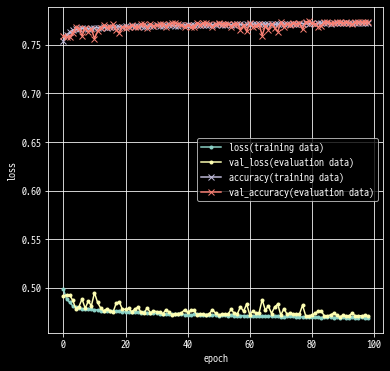

In [ ]:
callback = [EarlyStopping(monitor='val_loss', patience=20, verbose=1), ModelCheckpoint(filepath='best_model.h5', monitor='val_loss', save_best_only=True)]
tf.random.set_seed(9)

for i in [64]:
        model = Sequential()
        model.add(Dense(i,input_shape = (len(X_train_scaled.columns),),activation='relu'))
        model.add(Dense(i,activation='relu'))
        model.add(Dense(1,activation='sigmoid'))

        model.summary()

        model.compile(loss='binary_crossentropy',
                    optimizer='adam',
                    metrics=['accuracy',
                    tf.keras.metrics.Precision(name='precision'),
                    tf.keras.metrics.Recall(name='recall')])
        
        hist = model.fit(X_train_scaled, y_train,
                        batch_size=200,
                        epochs=100,
                        verbose=1,
                        validation_split=0.1,
                        callbacks=callback)
        score = model.evaluate(X_test_scaled, y_test, verbose=0)

        dnn = model.predict(X_test_scaled)
        dnn = pd.DataFrame(data=dnn).astype('float64')
        dnn[0]=dnn[0].apply(lambda x: 1 if x >= 0.5 else 0)
        # print(model.evaluate(X_test_scaled, y_test))
        f1 = f1_score(y_test, dnn)

        print(f'## DNN Node {i}-{i}, 활성화 함수 relu의 결과 ##')
        print(f'- Test LOSS : {score[0]}')
        print(f'- Test ACC : {score[1]}')
        print('- F1 score:',f1)
        
        loss = hist.history['loss'][1:]
        val_loss = hist.history['val_loss'][1:]
        accu = hist.history['accuracy'][1:]
        val_accu = hist.history['val_accuracy'][1:]
        epochs = len(loss)
        plt.rcParams["figure.figsize"] = (6,6)
        plt.plot(range(epochs), loss, marker='.', label='loss(training data)')
        plt.plot(range(epochs), val_loss, marker='.', label='val_loss(evaluation data)')
        plt.plot(range(epochs), accu, marker='x', label='accuracy(training data)')
        plt.plot(range(epochs), val_accu, marker='x', label='val_accuracy(evaluation data)')
        plt.legend(loc='best')
        plt.grid()
        plt.xlabel('epoch')
        plt.ylabel('loss')
        plt.show()
